# EDA de los modelos de victoria

Todo lo que se probó para predecir quién gana una partida, desde el primer baseline (20/10)
hasta hoy, ordenado alrededor de la pregunta con la que arrancó el proyecto (§1):

> ¿Qué predice mejor el resultado: el **draft** (qué campeones, en qué línea, contra qué) o los
> **jugadores** (quién está jugando y cómo viene jugando)?

Y una segunda pregunta que el proyecto también se hizo desde el principio: **cuánto se decide
durante la partida**, con el estado a los 10, 15 y 20 minutos.

**Datos.** Solo el train (`data/splits/train`); el test no se toca. Todo se mide en **V Master+**
(§9.S.51): las 16.428 partidas de Master+ del 16/09 al 27/09.

**Modelo.** Las secciones 2, 4, 5 y 6 usan el **escalón 9** del brainstorming (§9.S.52), el mejor
modelo previo: una logística ($C = 0{,}05$) entrenada solo con las partidas de Master+ anteriores al
16/09, sobre el draft, las 85 variables por jugador y las señales del brainstorming (márgenes
jugador-campeón y jugador-línea, nivel histórico, W/L de la foto, contracruces, winrate por línea,
Kalman-Elo, tempo, modelo por línea y duelo esperado). Reproduce `brainstorm_final.py`.

In [1]:
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display
from scipy import sparse, stats
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import log_loss, roc_auc_score

ROOT = Path.cwd().resolve()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

# Paleta y estilo del EDA del LP (eda_entre_fotos)
CATEGORICAL = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#6250d6", "#e34948"]
INK, INK_2, MUTED = "#0b0b0b", "#52514e", "#898781"
SIG = {"mejora": CATEGORICAL[0], "empeora": CATEGORICAL[7], "no significativo": MUTED, "sin IC": "#c3c2b7"}
COLOR_BLOQUE = {"Lado": MUTED, "Campeones": CATEGORICAL[1], "Jugadores": CATEGORICAL[0],
                "Jugador × campeón": CATEGORICAL[6], "Mixto": CATEGORICAL[3], "Escalón 9": CATEGORICAL[2]}
# Todos los gráficos con seaborn; el tema se ajusta a la paleta y al estilo de arriba
sns.set_theme(context="notebook", style="whitegrid", palette=CATEGORICAL)
plt.rcParams.update({
    "figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb",
    "axes.edgecolor": "#c3c2b7", "axes.labelcolor": INK_2, "axes.titlecolor": INK,
    "axes.titleweight": "bold", "axes.titlesize": 12, "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": "#e1e0d9", "grid.linewidth": 0.6, "axes.axisbelow": True,
    "xtick.color": INK_2, "ytick.color": INK_2, "text.color": INK,
    "legend.frameon": False, "figure.dpi": 110,
})
RESALTE = "background-color: #d8e8f8; color: #0b0b0b; font-weight: bold"
FMT_AUC = {"AUC": "{:.4f}", "Accuracy": "{:.1%}"}

cache = ROOT / "data" / "analysis" / "embeddings_partidas" / "variables.npz"
if not cache.exists():
    raise FileNotFoundError("Falta la caché: correr  python scripts/analysis/embeddings_partidas.py")
Z = np.load(cache, allow_pickle=True)
Xj, cols, y, val, tnum, champ = Z["Xj"], list(Z["cols"]), Z["y"], Z["val"], Z["tnum"], Z["champ"]
D = {k[2:]: Z[k] for k in Z.files if k.startswith("D_")}
NM, d = len(y), Xj.shape[-1]

# Partición y señales del escalón 9 (scripts/analysis/brainstorm_base.py, brainstorm_final.py)
from scripts.analysis.brainstorm_base import cargar, extras_referencia
E9 = cargar()
X9 = extras_referencia(E9, escalon=9)
val = E9["val"]                                            # V Master+
fit = np.zeros(NM, bool)
fit[E9["fi_v"][E9["master"][E9["fi_v"]]]] = True           # Master+ anterior al 16/09
yv = y[val]
print(f"{NM:,} partidas completas del train. Escalón 9: ajuste {fit.sum():,} (Master+ anterior al 16/09), "
      f"V Master+ {val.sum():,}. Gana azul en V: {yv.mean():.1%}.")

Cobertura Foto 1 en post: has_f1=91.72%, zero_m=2.39%


187,817 partidas completas del train. Escalón 9: ajuste 118,064 (Master+ anterior al 16/09), V Master+ 16,428. Gana azul en V: 47.8%.


In [2]:
# Herramientas comunes: logística, bootstrap pareado y tabla de métricas
B = 400
BOOT = np.random.default_rng(1).integers(0, len(yv), size=(B, len(yv)))


# Diseño del escalón 9: [draft | 85 variables × 5 líneas (azul − rojo) | señales del brainstorming],
# estandarizado con las filas de ajuste (igual que brainstorm_base.ajustar_predecir sin el mapa)
DRAFT = E9["DRAFT"].tocsr()
nd = DRAFT.shape[1]
Xd = (Xj[:, 0] - Xj[:, 1]).reshape(NM, -1).astype(np.float32)            # columna = línea * d + variable
Xd = (Xd - Xd[fit].mean(0)) / (Xd[fit].std(0) + 1e-6)
X9s = ((X9 - X9[fit].mean(0)) / (X9[fit].std(0) + 1e-6)).astype(np.float32)
XALL = sparse.hstack([DRAFT, sparse.csr_matrix(Xd), sparse.csr_matrix(X9s)]).tocsr()
fi_idx, vi_idx = np.flatnonzero(fit), np.flatnonzero(val)
X_fit, X_val = XALL[fi_idx], XALL[vi_idx]

# Qué es cada columna extra del escalón 9 (orden de extras_referencia(escalon=9))
n_foto = E9["_ref"].shape[1] - 153
PARTES9 = [("Margen jugador-campeón", "Jugador × campeón", 75), ("Margen jugador-línea", "Jugadores", 75),
           ("Nivel histórico", "Jugadores", 3), ("W/L de la foto", "Jugadores", n_foto),
           ("Contracruces y sinergias", "Campeones", 10), ("WR por línea y autofill", "Jugadores", 10),
           ("Kalman-Elo", "Jugadores", 19), ("Tempo y objetivos", "Jugadores", 10),
           ("Economía 15→20", "Jugadores", 4), ("Modelo por línea", "Mixto", 6),
           ("Duelo esperado", "Campeones", 12)]
assert sum(n for *_, n in PARTES9) == X9.shape[1], (sum(n for *_, n in PARTES9), X9.shape[1])
fam9 = np.concatenate([[f] * n for f, _, n in PARTES9])
blo9 = np.concatenate([[b] * n for _, b, n in PARTES9])


def logistica(mask, C=0.05, idx_fit=None, idx_eval=None, devolver_modelo=False):
    # mask: columnas de XALL que entran; ajusta con Master+ anterior al 16/09 y predice V Master+
    Xf = X_fit if idx_fit is None else XALL[idx_fit]
    Xe = X_val if idx_eval is None else XALL[idx_eval]
    yf = y[fi_idx] if idx_fit is None else y[idx_fit]
    cols_ = np.flatnonzero(mask)
    lr = LogisticRegression(C=C, max_iter=4000).fit(Xf[:, cols_], yf)
    p = lr.predict_proba(Xe[:, cols_])[:, 1]
    return (p, lr) if devolver_modelo else p


def auc_boot(p, yy=None, boot=None):
    yy = yv if yy is None else yy
    boot = BOOT if boot is None else boot
    return np.array([roc_auc_score(yy[s], p[s]) for s in boot])


def metricas(preds, yy=None):
    yy = yv if yy is None else yy
    filas = [{"modelo": n, "AUC": roc_auc_score(yy, p), "Accuracy": ((p > 0.5) == yy).mean()} for n, p in preds.items()]
    return pd.DataFrame(filas).set_index("modelo")


def diferencia(p1, p0, yy=None, boot=None):
    # ΔAUC con su IC 95 % por bootstrap pareado (el IC no se muestra en las tablas; se usa para
    # decidir si una diferencia es significativa)
    yy = yv if yy is None else yy
    boot = BOOT if boot is None else boot
    b = np.array([roc_auc_score(yy[s], p1[s]) - roc_auc_score(yy[s], p0[s]) for s in boot])
    return roc_auc_score(yy, p1) - roc_auc_score(yy, p0), np.percentile(b, 2.5), np.percentile(b, 97.5)


Z95 = 1.959963984540054


def wilson_ci(p, n, z=Z95):
    # IC 95 % de Wilson para una proporción (acepta escalares o arrays)
    p = np.asarray(p, dtype=float)
    n = np.asarray(n, dtype=float)
    denom = 1.0 + z * z / n
    centro = (p + z * z / (2.0 * n)) / denom
    semi = z * np.sqrt(np.maximum(p * (1.0 - p) / n + z * z / (4.0 * n * n), 0.0)) / denom
    return np.clip(centro - semi, 0.0, 1.0), np.clip(centro + semi, 0.0, 1.0)


def hanley_mcneil_ci(auc, n1, n0, z=Z95):
    # IC 95 % de Hanley-McNeil (1982) para AUC cuando solo se dispone de AUC, n1 y n0
    a = np.asarray(auc, dtype=float)
    n1 = np.asarray(n1, dtype=float)
    n0 = np.asarray(n0, dtype=float)
    q1 = a / (2.0 - a)
    q2 = 2.0 * a * a / (1.0 + a)
    var = (a * (1.0 - a) + (n1 - 1.0) * (q1 - a * a) + (n0 - 1.0) * (q2 - a * a)) / (n1 * n0)
    se = np.sqrt(np.maximum(var, 0.0))
    return np.clip(a - z * se, 0.0, 1.0), np.clip(a + z * se, 0.0, 1.0)


def mean_ci(x, z=Z95):
    # IC 95 % normal de la media (media ± 1,96·EE) ignorando NaN
    a = np.asarray(x, dtype=float)
    a = a[np.isfinite(a)]
    m = float(a.mean())
    se = float(a.std(ddof=1) / np.sqrt(len(a))) if len(a) > 1 else 0.0
    return m, m - z * se, m + z * se


def median_ci(x, z=Z95):
    # IC 95 % de la mediana por estadísticos de orden
    a = np.asarray(x, dtype=float)
    a = a[np.isfinite(a)]
    h = min(0.499, z * 0.5 / np.sqrt(len(a)))
    lo, med, hi = np.quantile(a, [0.5 - h, 0.5, 0.5 + h])
    return float(med), float(lo), float(hi)

# 1. El camino: del primer baseline al modelo de hoy

Los ocho modelos que marcan el camino, **todos medidos igual** y sin tocar el test
(`scripts/analysis/modelos_train_v.py`, PROJECT_SUMMARY.md §9.S.55):

* **V** = V Master+ (§9.S.51): las 16.428 partidas de Master+ del 16/09 al 27/09, las mismas para
  todos. Cada modelo predice V entrenado solo con partidas anteriores al 16/09.
* **Train** = dentro de la muestra: el mismo modelo, evaluado sobre las partidas con que se ajustó.
  La distancia entre Train y V mide cuánto se aprendió de memoria.

| Modelo | Qué es |
| :--- | :--- |
| **Baseline** | Siempre el rojo (el lado que gana un poco más) |
| **Regla** | Media del winrate de cada campeón en su línea, sin leakage (§9.S.13) |
| **Logística Draft** | Campeón × línea con signo, Bradley-Terry (§9.S.20) |
| **Campeones** | One-hot de los campeones con signo (§9.S.23) |
| **Campeones + Jugador** | Campeones + LP de la foto + huella de estilo (§9.S.23) |
| **Stacking** | Margen por campeón + stacking de 6 expertos, logísticas y redes (§9.S.29) |
| **MOE** | 2 expertos (red de grupos + logística) + composición del draft + modelo por línea (§9.S.37) |
| **Logística Master+ (Elo y duelos)** | Escalón 9 del brainstorming: entrena solo con Master+ y suma margen jugador-campeón, nivel histórico, W/L de la foto, contracruces, Kalman-Elo, tempo, modelo por línea y margen esperado de cada duelo (§9.S.52) |

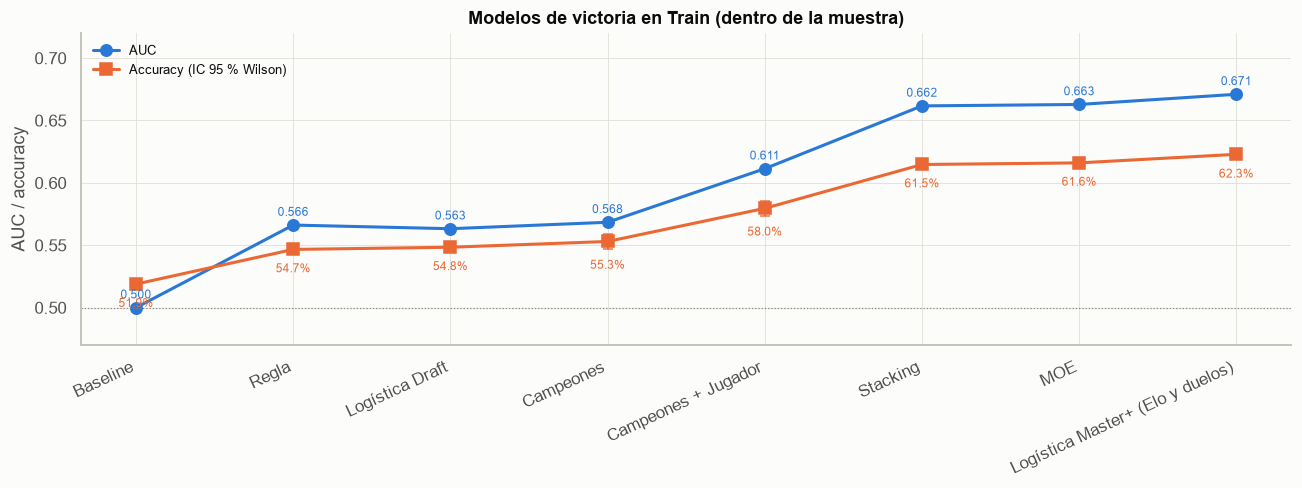

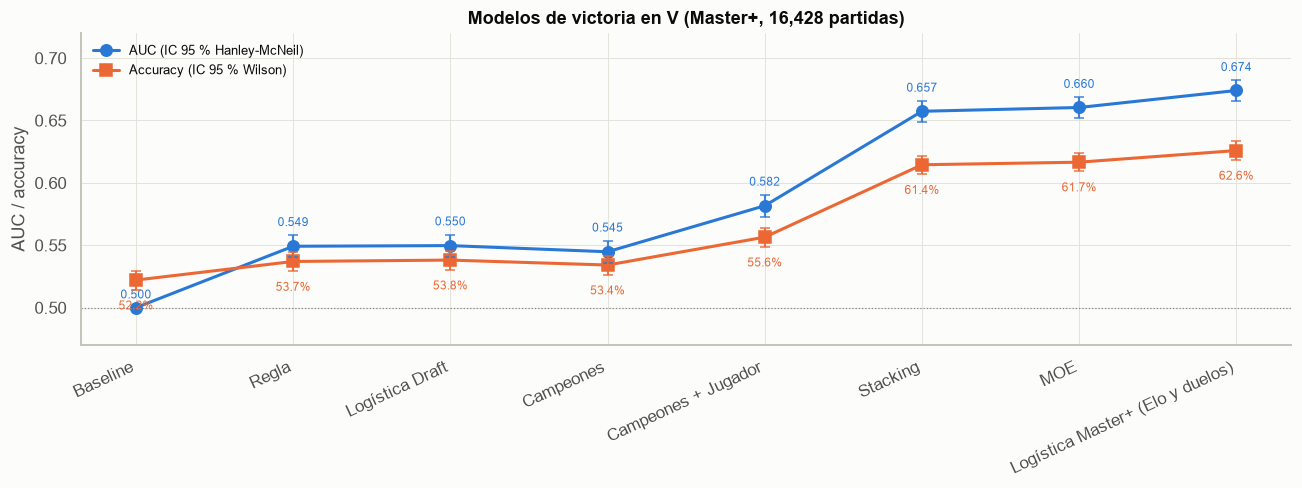

In [3]:
ruta_m = ROOT / "data" / "analysis" / "modelos_train_v.csv"
mtv = pd.read_csv(ruta_m) if ruta_m.exists() else pd.DataFrame(columns=["modelo", "AUC train", "acierto train",
                                                                          "AUC V", "acierto V", "n train", "n V"])
if mtv.empty:
    print("Falta la tabla: correr  python scripts/analysis/modelos_train_v.py  (la sección 1 queda vacía)")
ORDEN_MOD = list(mtv.modelo)
largo = mtv.melt(id_vars="modelo", value_vars=["AUC train", "acierto train", "AUC V", "acierto V"],
                 var_name="col", value_name="valor")
largo["conjunto"] = largo.col.str.split().str[1].map({"train": "Train", "V": "V"})
largo["métrica"] = largo.col.str.split().str[0].map({"AUC": "AUC", "acierto": "Accuracy"})
largo["modelo"] = pd.Categorical(largo.modelo, ORDEN_MOD, ordered=True)
COLOR_MET = {"AUC": CATEGORICAL[0], "Accuracy": CATEGORICAL[1]}

for conj in ("Train", "V") if len(mtv) else ():
    s = largo[largo.conjunto == conj].sort_values("modelo").copy()
    n_col = "n V" if conj == "V" else "n train"
    n_map = mtv.set_index("modelo")[n_col]
    n_pos_v = int(yv.sum())
    lo_s, hi_s = [], []
    for _, r in s.iterrows():
        n_m = float(n_map[r.modelo])
        if r["métrica"] == "Accuracy":
            lo_, hi_ = wilson_ci(r.valor, n_m)
        elif conj == "V" and r.modelo != "Baseline" and n_m == len(yv):
            lo_, hi_ = hanley_mcneil_ci(r.valor, n_pos_v, len(yv) - n_pos_v)
        else:
            # En Train, el CSV no trae la cantidad de positivos por modelo.
            lo_, hi_ = np.nan, np.nan
        lo_s.append(float(lo_)); hi_s.append(float(hi_))
    s["lo"], s["hi"] = lo_s, hi_s
    fig, ax = plt.subplots(figsize=(12, 4.6))
    auc_label = "AUC (IC 95 % Hanley-McNeil)" if conj == "V" else "AUC"
    for met, mk, lbl_ic in (("AUC", "o", auc_label),
                            ("Accuracy", "s", "Accuracy (IC 95 % Wilson)")):
        sm = s[s["métrica"] == met].sort_values("modelo")
        xs = np.array([ORDEN_MOD.index(m) for m in sm.modelo])
        ys = sm.valor.to_numpy()
        ax.plot(xs, ys, marker=mk, color=COLOR_MET[met], lw=2, markersize=7.5, label=lbl_ic)
        ok_ic = np.isfinite(sm.lo.to_numpy()) & np.isfinite(sm.hi.to_numpy())
        if ok_ic.any():
            ax.fill_between(xs, sm.lo.to_numpy(float), sm.hi.to_numpy(float), where=ok_ic,
                            color=COLOR_MET[met], alpha=0.15, lw=0, zorder=1)
        for xi, (_, r) in zip(xs, sm.iterrows()):
            y_ref = r.hi if (met == "AUC" and np.isfinite(r.hi)) else (r.lo if (met == "Accuracy" and np.isfinite(r.lo)) else r.valor)
            ax.annotate(f"{r.valor:.3f}" if met == "AUC" else f"{r.valor:.1%}",
                        (xi, y_ref), textcoords="offset points",
                        xytext=(0, 6 if met == "AUC" else -13), ha="center", fontsize=8,
                        color=COLOR_MET[met])
    ax.axhline(0.5, color=MUTED, lw=0.8, ls=":")
    y_top = float(np.nanmax(np.r_[s.valor.to_numpy(), s.hi.to_numpy()]))
    ax.set_ylim(0.47, max(0.72, y_top + 0.025))
    ax.set_xlabel("")
    ax.set_ylabel("AUC / accuracy")
    ax.set_xticks(range(len(ORDEN_MOD)), ORDEN_MOD, rotation=25, ha="right")
    n = mtv["n V"].iloc[0] if conj == "V" else None
    ax.set_title(f"Modelos de victoria en {conj}" + (f" (Master+, {n:,} partidas)" if n else " (dentro de la muestra)"))
    ax.legend(title="", loc="upper left", fontsize=8.5)
    plt.tight_layout()
    plt.show()

In [4]:
tab_mtv = mtv.set_index("modelo")[["AUC train", "acierto train", "AUC V", "acierto V", "n train", "n V"]]
tab_mtv.insert(4, "Δ AUC (train − V)", tab_mtv["AUC train"] - tab_mtv["AUC V"])
tab_mtv.columns = ["AUC Train", "Accuracy Train", "AUC V", "Accuracy V", "Δ AUC (Train − V)", "n Train", "n V"]
display(tab_mtv.style.format({"AUC Train": "{:.4f}", "AUC V": "{:.4f}", "Accuracy Train": "{:.1%}",
                              "Accuracy V": "{:.1%}", "Δ AUC (Train − V)": "{:+.4f}", "n Train": "{:,}", "n V": "{:,}"})
        .highlight_max(subset=["AUC V", "Accuracy V"], props=RESALTE)
        .set_caption("Los ocho modelos en Train y en V (V Master+, la misma para todos)"))

,AUC Train,Accuracy Train,AUC V,Accuracy V,Δ AUC (Train − V),n Train,n V
modelo,,,,,,,
Baseline,0.5000,51.9%,0.5000,52.2%,+0.0000,"160,883","16,428"
Regla,0.5662,54.7%,0.5492,53.7%,+0.0170,"160,883","16,428"
Logística Draft,0.5632,54.8%,0.5497,53.8%,+0.0135,"160,883","16,428"
Campeones,0.5684,55.3%,0.5448,53.4%,+0.0236,"26,934","16,428"
Campeones + Jugador,0.6113,58.0%,0.5817,55.6%,+0.0297,"26,934","16,428"
Stacking,0.6617,61.5%,0.6574,61.4%,+0.0043,"160,885","16,428"
MOE,0.6628,61.6%,0.6604,61.7%,+0.0024,"160,885","16,428"
Logística Master+ (Elo y duelos),0.6710,62.3%,0.6740,62.6%,-0.0031,"118,064","16,428"


**Lectura.**

* **Todo lo que es solo draft se queda en ~0,55 de AUC y ~54 % de acierto en V** (Regla 0,549 / 53,7 %,
  Logística Draft 0,550 / 53,8 %, Campeones 0,545 / 53,4 %), apenas arriba del Baseline (52,2 %, la tasa
  del lado). Saber quién juega es lo que mueve la aguja: Campeones + Jugador sube a 0,582 / 55,6 %, el
  Stacking a 0,657 / 61,4 % y el MOE a 0,660 / 61,7 %. Desde ahí cada paso es información del
  historial del jugador mejor resumida.
* **El modelo final llega a 0,674 / 62,6 % en V Master+**, +0,014 de AUC y +0,9 puntos sobre el MOE. Es
  el único que entrena solo con Master+ y que suma la fuerza del jugador estimada en el tiempo
  (Kalman-Elo) y lo que se espera de cada duelo de línea.
* **Train contra V.** En la Regla y la Logística Draft la distancia es de 0,014-0,017 de AUC; en
  Campeones y Campeones + Jugador sube a 0,024-0,030, porque se ajustaron solo con las 26.934
  partidas posteriores a la foto (necesitan el LP de la foto). En el Stacking y el MOE es de apenas
  0,002-0,004: las variables por jugador vienen regularizadas (margen encogido, empírico-bayesiano) y
  el meta se ajusta fuera de muestra. En el modelo final, V incluso supera a Train (0,674 contra
  0,671). La explicación más probable (no medida acá) es que el ajuste arranca antes, con
  historiales más cortos, y en V cada jugador ya acumuló más partidas previas, que es justo lo que
  el modelo aprovecha. Ninguno de los modelos de jugadores muestra sobreajuste.
* Los números de V de esta tabla pueden diferir de los de cada sección de PROJECT_SUMMARY.md: allá la
  V tenía todas las ligas (26.934 partidas), y acá todos se miden en la V de Master+.

# 2. La pregunta central: campeones contra jugadores

Las columnas del escalón 9 repartidas en bloques de información, todos **antes de la partida** y
todos calculados con partidas anteriores a la que se predice:

| Bloque | Qué tiene | Variables |
| :--- | :--- | :--- |
| **Campeones** | El draft, sin saber quién juega | campeón × línea con signo (Bradley-Terry, como §9.S.20), atributos de Data Dragon, perfil de estilo típico de cada campeón, contracruces y sinergias, y el margen esperado de cada duelo de línea según el par de campeones |
| **Jugadores** | Quién juega, sin saber con qué | margen previo (acumulado, últimas 20 y por línea), winrate previo y por línea, partidas totales, porción de la línea, fuera de rol, pool, ritmo y descanso, nivel histórico, W/L de la foto, Kalman-Elo, tempo y economía 15→20 |
| **Jugador × campeón** | Cómo le va a ese jugador con ese campeón | partidas con el campeón, estreno, porción del campeón, winrate y margen con el campeón |
| **Escalón 9** | Todo junto, más el modelo por línea (oro a los 15 predicho con jugadores y campeones a la vez) | — |

Un campeón en manos de un especialista no es el mismo campeón que en manos de alguien que lo
estrena: el bloque jugador × campeón mide esa interacción. Todo entra como azul − rojo por línea,
en una logística con la misma regularización ($C = 0{,}05$), entrenada con Master+ anterior al 16/09.

In [5]:
JUGADOR_CAMPEON = {"logn_champ", "estreno", "wr_champ", "share_champ"}
CAMPEON_PREF = ("tag_", "info_", "st_", "perf_")


def bloque(c):
    if c.startswith(CAMPEON_PREF):
        return "Campeones"
    if c in JUGADOR_CAMPEON:
        return "Jugador × campeón"
    return "Jugadores"


# bloque de cada columna de XALL: draft, 85 variables × 5 líneas y señales del brainstorming
blo = np.concatenate([["Draft"] * nd, np.tile(np.array([bloque(c) for c in cols]), 5), blo9])
print(f"Draft: {nd:,} pares (campeón, línea). Columnas por bloque:",
      pd.Series(blo).value_counts().to_dict())

Draft: 851 pares (campeón, línea). Columnas por bloque: {'Draft': 851, 'Jugadores': 330, 'Campeones': 222, 'Jugador × campeón': 95, 'Mixto': 6}


In [6]:
es_campeon = np.isin(blo, ["Draft", "Campeones"])
P = {}
P["Lado (siempre la tasa del azul)"] = np.full(len(yv), y[fit].mean())
P["Campeones: solo draft"] = logistica(blo == "Draft")
P["Campeones: draft + atributos + cruces"] = logistica(es_campeon)
P["Jugadores"] = logistica(blo == "Jugadores")
P["Jugador × campeón"] = logistica(blo == "Jugador × campeón")
P["Jugadores + jugador × campeón"] = logistica(np.isin(blo, ["Jugadores", "Jugador × campeón"]))
P["Escalón 9: todo"], lr9 = logistica(np.ones(len(blo), bool), devolver_modelo=True)
P9 = P["Escalón 9: todo"]
tab = metricas(P)
display(tab.style.format(FMT_AUC).set_caption("Cada bloque solo y todo junto (V Master+)")
        .highlight_max(subset=["AUC", "Accuracy"], props=RESALTE))

,AUC,Accuracy
modelo,,
Lado (siempre la tasa del azul),0.5000,52.2%
Campeones: solo draft,0.5490,53.9%
Campeones: draft + atributos + cruces,0.5592,54.8%
Jugadores,0.6394,59.6%
Jugador × campeón,0.5971,57.1%
Jugadores + jugador × campeón,0.6619,61.7%
Escalón 9: todo,0.6740,62.6%


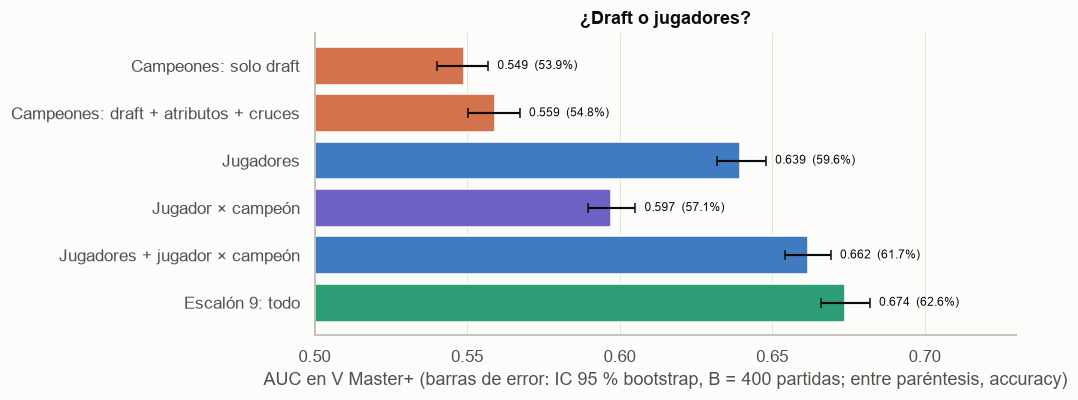

modelo,contra,qué agrega,ΔAUC,ΔAccuracy
Jugadores,Campeones: draft + atributos + cruces,Quién juega (sin saber con qué campeón) en lugar del draft,+0.0802,+4.84%
Jugadores + jugador × campeón,Campeones: draft + atributos + cruces,"Quién juega y cómo le va con su campeón, en lugar del draft",+0.1027,+6.91%
Escalón 9: todo,Jugadores + jugador × campeón,"El draft y el modelo por línea, encima de todo lo del jugador",+0.0122,+0.93%
Escalón 9: todo,Campeones: draft + atributos + cruces,"Todo lo del jugador, encima del draft",+0.1149,+7.83%
Campeones: draft + atributos + cruces,Campeones: solo draft,"Atributos, perfil de estilo, contracruces y duelo esperado, encima del draft",+0.0101,+0.84%


Nota: en 4 de 5 comparaciones el límite superior del IC 95 % (bootstrap pareado) se aleja del Δ más que el inferior: el IC es asimétrico hacia arriba.


In [7]:
fig, (ax, ax_acc) = plt.subplots(1, 2, figsize=(14, 3.8), sharey=True)
t = tab.iloc[1:].reset_index()
t["bloque"] = ["Campeones"] * 2 + ["Jugadores", "Jugador × campeón", "Jugadores", "Escalón 9"]
ic_b = np.array([np.percentile(auc_boot(P[m]), [2.5, 97.5]) for m in t["modelo"]])
t["lo"], t["hi"] = ic_b[:, 0], ic_b[:, 1]
t["acc_lo"], t["acc_hi"] = wilson_ci(t["Accuracy"].to_numpy(), len(yv))

# Izquierda: AUC (IC 95 % bootstrap por partida)
sns.barplot(data=t, x="AUC", y="modelo", hue="bloque", palette=COLOR_BLOQUE, dodge=False, legend=False, ax=ax)
ax.errorbar(t["AUC"], np.arange(len(t)), xerr=[t["AUC"] - t["lo"], t["hi"] - t["AUC"]],
            fmt="none", ecolor=INK, elinewidth=1.4, capsize=3.5, zorder=5)
for yi, (a, hi) in enumerate(zip(t.AUC, t.hi)):
    ax.text(hi + 0.003, yi, f"{a:.3f}", va="center", fontsize=8)
ax.set_ylabel("")
ax.set_xlim(0.5, max(t.hi) + 0.03)
ax.set_xlabel(f"AUC en V Master+ (IC 95 % bootstrap, B = {B} partidas)")
ax.set_title("¿Draft o jugadores? AUC", loc="left")

# Derecha: accuracy (IC 95 % Wilson, n = partidas de V); la línea punteada es siempre apostar al azul
acc_lado = float(tab["Accuracy"].iloc[0])
sns.barplot(data=t, x="Accuracy", y="modelo", hue="bloque", palette=COLOR_BLOQUE, dodge=False, legend=False,
            ax=ax_acc)
ax_acc.errorbar(t["Accuracy"], np.arange(len(t)),
                xerr=[np.maximum(0.0, t["Accuracy"] - t["acc_lo"]), np.maximum(0.0, t["acc_hi"] - t["Accuracy"])],
                fmt="none", ecolor=INK, elinewidth=1.4, capsize=3.5, zorder=5)
ax_acc.axvline(acc_lado, color=MUTED, ls=":", lw=1.2)
ax_acc.text(acc_lado, 1.01, f"siempre azul {acc_lado:.1%}", transform=ax_acc.get_xaxis_transform(),
            fontsize=7.8, color=INK_2, ha="center", va="bottom")
for yi, (ac, hi) in enumerate(zip(t.Accuracy, t.acc_hi)):
    ax_acc.text(hi + 0.002, yi, f"{ac:.1%}", va="center", fontsize=8)
ax_acc.set_ylabel("")
ax_acc.set_xlim(0.5, max(t.acc_hi) + 0.02)
ax_acc.xaxis.set_major_formatter(plt.matplotlib.ticker.PercentFormatter(1, decimals=0))
ax_acc.set_xlabel(f"Accuracy en V Master+ (IC 95 % Wilson, n = {len(yv):,} partidas)".replace(",", ".").replace("Wilson.", "Wilson,"))
ax_acc.set_title("Accuracy de cada modelo", loc="left", pad=14)
plt.tight_layout()
plt.show()

# Cada fila: el modelo de la izquierda contra el de la derecha, y qué información le suma el primero
comp = [("Jugadores", "Campeones: draft + atributos + cruces",
         "Quién juega (sin saber con qué campeón) en lugar del draft"),
        ("Jugadores + jugador × campeón", "Campeones: draft + atributos + cruces",
         "Quién juega y cómo le va con su campeón, en lugar del draft"),
        ("Escalón 9: todo", "Jugadores + jugador × campeón",
         "El draft y el modelo por línea, encima de todo lo del jugador"),
        ("Escalón 9: todo", "Campeones: draft + atributos + cruces",
         "Todo lo del jugador, encima del draft"),
        ("Campeones: draft + atributos + cruces", "Campeones: solo draft",
         "Atributos, perfil de estilo, contracruces y duelo esperado, encima del draft")]
acc = lambda p: ((p > 0.5) == yv).mean()  # noqa: E731
filas, asim = [], []
for a, b, que in comp:
    dlt, lo, hi = diferencia(P[a], P[b])
    asim.append((hi - dlt) > (dlt - lo))
    filas.append({"modelo": a, "contra": b, "qué agrega": que, "ΔAUC": dlt, "ΔAccuracy": acc(P[a]) - acc(P[b])})
display(pd.DataFrame(filas).style.format({"ΔAUC": "{:+.4f}", "ΔAccuracy": "{:+.2%}"})
        .hide(axis="index").set_caption("Diferencias pareadas (V): modelo − contra"))
print(f"Nota: en {sum(asim)} de {len(asim)} comparaciones el límite superior del IC 95 % (bootstrap pareado) "
      "se aleja del Δ más que el inferior: el IC es asimétrico hacia arriba.")

**Lectura.**

* **Los jugadores le ganan al draft por mucho.** Todo lo de campeones junto (draft, atributos,
  estilo, contracruces y duelo esperado) llega a 0,559 / 54,8 %. Los jugadores solos, sin saber con
  qué campeón juegan, a 0,639 / 59,6 % (+0,080), y con *jugador × campeón* a 0,662 / 61,7 % (+0,103).
  Los dos bloques de jugador le sacan al draft más del doble de lo que el draft le saca a una moneda.
* Solo *jugador × campeón* (partidas, estreno, porción, winrate y margen con el campeón) predice más
  que todo el bloque de campeones: 0,597 contra 0,559.
* Sumarle a los jugadores el draft y el modelo por línea agrega +0,012 (0,662 → 0,674): poco al lado
  de los jugadores, pero significativo. Casi todo lo que el draft dice del resultado ya está en
  *quién* lo juega y *cómo le va con ese campeón*.
* Dentro de los campeones, lo que suma sobre el draft solo son los cruces: contracruces, sinergias y
  margen esperado de cada duelo de línea (+0,010, de 0,549 a 0,559). Los atributos y el estilo solos
  no lo movían (§9.S.42). El draft, en SoloQ de alto elo, sigue siendo una señal débil.

# 3. Cuánto se decide durante la partida

El estado de la partida en el minuto 10, 15 y 20 (oro, experiencia, kills, CS, daño y nivel por
línea, azul − rojo, el oro que no explican CS y kills, y cómo vienen cambiando desde el minuto
anterior) contra el **modelo en vivo
vigente** (§9.S.60), que además sabe todo lo previo. Muestra cuánto del resultado está todavía sin
decidir antes de jugar.

* *Solo el estado:* logística sobre el estado, **sin nada previo** (`ingame_estado_puro.py`).
* *Lo previo + el estado:* el modelo en vivo vigente (`ingame_g_04_mt_a4_gpu.py`): ensamble de una
  logística y tres redes multitarea que reciben el logit de un modelo previo simplificado, más una
  segunda etapa con el ensamble del escalón 10. Las cifras a los 10, 15 y 20 minutos corresponden al
  ajuste en vivo de §9.S.60, anterior a la corrección. "Antes" es el escalón 9 corregido (§9.S.68), en toda V.

Mismas partidas de V Master+ en las dos barras (solo las que siguen vivas en el minuto); no se
reentrena nada acá. Cada barra muestra lo que da **solo el estado** y, apilado encima, lo que suma
**lo previo**.

,AUC solo el estado,AUC previo + estado,Accuracy solo el estado,Accuracy previo + estado
momento,,,,
antes,—,0.6740,—,62.6%
minuto 10,0.7517,0.7912,68.7%,71.6%
minuto 15,0.8189,0.8441,73.7%,76.1%
minuto 20,0.8586,0.8750,77.4%,79.1%


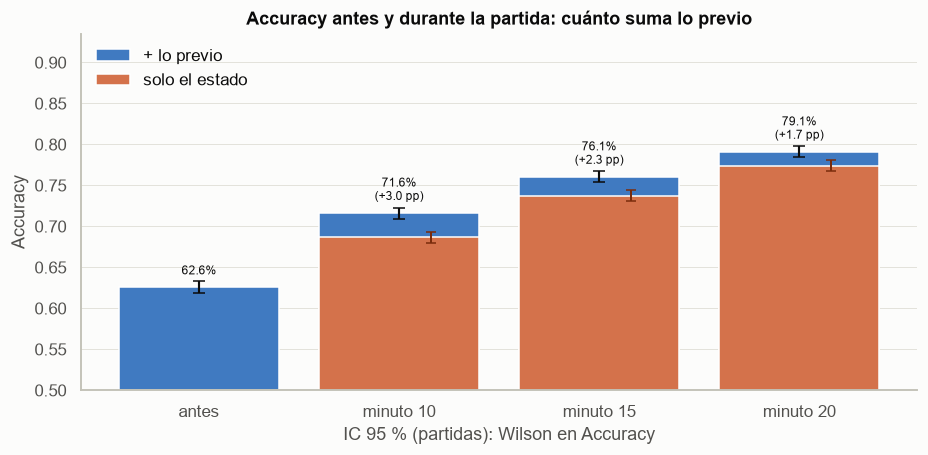

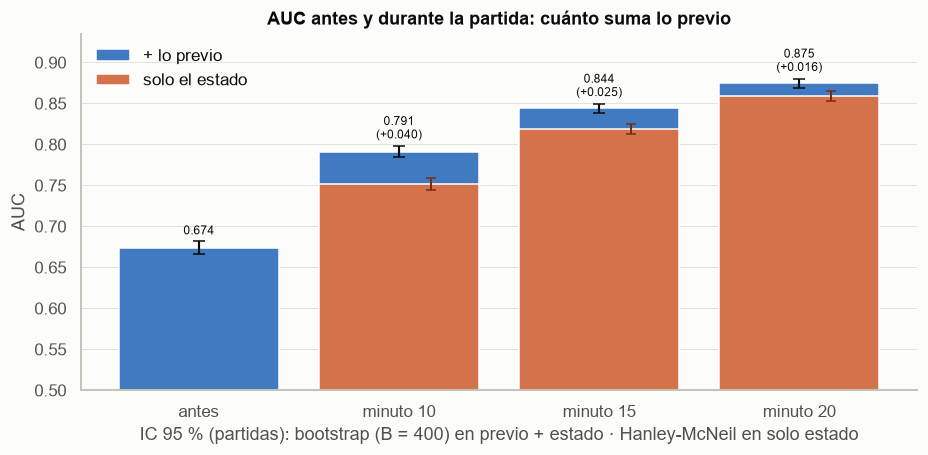

In [8]:
# V Master+ (PROJECT_SUMMARY.md §9.S.60): estado solo de ingame_estado_puro.py, vigente de ingame_g_04_mt_a4_gpu.py
with np.load(ROOT / "data" / "analysis" / "brainstorm" / "pred_final.npz") as previo:
    if not np.array_equal(previo["idx_v"], vi_idx):
        raise ValueError("Las predicciones de brainstorm_final.py no coinciden con las filas de V Master+.")
    p_antes = previo["p_v"]
vivo = pd.DataFrame({
    "momento": ["antes", "minuto 10", "minuto 15", "minuto 20"],
    "AUC solo el estado": [0.5, 0.751651, 0.818900, 0.858573],
    "AUC previo + estado": [roc_auc_score(yv, p_antes), 0.791198, 0.844131, 0.874981],
    "Accuracy solo el estado": [0.5, 0.686547, 0.737406, 0.773896],
    "Accuracy previo + estado": [((p_antes > 0.5) == yv).mean(), 0.716061, 0.760623, 0.791196],
}).set_index("momento")
t3 = vivo.copy()
t3.loc["antes", ["AUC solo el estado", "Accuracy solo el estado"]] = np.nan   # antes no hay estado
display(t3.style.format("{:.4f}", subset=[c for c in t3.columns if c.startswith("AUC")], na_rep="—")
        .format("{:.1%}", subset=[c for c in t3.columns if c.startswith("Acc")], na_rep="—")
        .set_caption("Modelo antes y durante la partida (V Master+)"))

# Intervalos condicionales a las predicciones archivadas y a la cohorte de cada minuto.
_ig_dir = ROOT / "data" / "analysis" / "ingame"
_n_vivo = {"antes": len(yv)}
_n1_estado = {}
_est_csv = _ig_dir / "estado_puro.csv"
if _est_csv.exists():
    _estados = pd.read_csv(_est_csv)
    _estados = _estados[_estados["modelo"] == "estado_completo"].set_index("minuto")
    for m_ in (10, 15, 20):
        _n_vivo[f"minuto {m_}"] = int(_estados.loc[m_, "n_V"])
_pred_mt = _ig_dir / "pred_mt_a4_gpu_92k.npz"
_pred_ig = _ig_dir / "pred_ingame.npz"
_auc_tot_ci = {"antes": tuple(np.percentile(auc_boot(p_antes), [2.5, 97.5]))}
if _pred_mt.exists():
    _rng_v = np.random.default_rng(3)
    with np.load(_pred_mt) as _zm:
        for m_ in (10, 15, 20):
            mom_ = f"minuto {m_}"
            ym_ = _zm[f"y_v_{m_}"].astype(int)
            pm_ = _zm[f"pv_{m_}_6_Final_dEns10"]
            acc_ = ((pm_ > 0.5) == ym_).mean()
            auc_ = roc_auc_score(ym_, pm_)
            if np.allclose([auc_, acc_], vivo.loc[mom_, ["AUC previo + estado", "Accuracy previo + estado"]],
                           rtol=0, atol=1e-6):
                _n_vivo[mom_] = len(ym_)
                bm_ = _rng_v.integers(0, len(ym_), size=(B, len(ym_)))
                _auc_tot_ci[mom_] = tuple(np.percentile(auc_boot(pm_, ym_, bm_), [2.5, 97.5]))
if _est_csv.exists() and _pred_ig.exists():
    with np.load(_pred_ig) as _zi:
        for m_ in (10, 15, 20):
            mom_ = f"minuto {m_}"
            ym_ = _zi[f"y_v_{m_}"].astype(int)
            if len(ym_) == int(_estados.loc[m_, "n_V"]) == _n_vivo.get(mom_):
                _n1_estado[mom_] = int(ym_.sum())

for met in ("Accuracy", "AUC"):
    fig, ax = plt.subplots(figsize=(8.6, 4.3))
    s = vivo.reset_index()
    # barras apiladas con seaborn: primero el total (previo + estado) y encima la parte del estado solo
    sns.barplot(data=s, x="momento", y=f"{met} previo + estado", color=CATEGORICAL[0], label="+ lo previo", ax=ax)
    sns.barplot(data=s, x="momento", y=f"{met} solo el estado", color=CATEGORICAL[1], label="solo el estado", ax=ax)
    for i, r in s.iterrows():
        mom = r["momento"]
        tot, sol = r[f"{met} previo + estado"], r[f"{met} solo el estado"]
        nm_ = _n_vivo.get(mom)
        n1_ = _n1_estado.get(mom)
        lo_t, hi_t = np.nan, np.nan
        lo_s, hi_s = np.nan, np.nan
        if met == "Accuracy" and nm_:
            lo_t, hi_t = wilson_ci(tot, nm_)
            if i > 0:
                lo_s, hi_s = wilson_ci(sol, nm_)
        elif met == "AUC":
            lo_t, hi_t = _auc_tot_ci.get(mom, (np.nan, np.nan))
            if n1_ and nm_ and n1_ < nm_:
                lo_s, hi_s = hanley_mcneil_ci(sol, n1_, nm_ - n1_)
        if np.isfinite(lo_t):
            ax.errorbar(i, tot, yerr=[[max(0.0, tot - lo_t)], [max(0.0, hi_t - tot)]],
                        fmt="none", ecolor=INK, elinewidth=1.4, capsize=4, zorder=5)
        if np.isfinite(lo_s):
            ax.errorbar(i + 0.16, sol, yerr=[[max(0.0, sol - lo_s)], [max(0.0, hi_s - sol)]],
                        fmt="none", ecolor="#7a2c0c", elinewidth=1.3, capsize=3.5, zorder=5)
        if met == "Accuracy":
            txt = f"{tot:.1%}" + ("" if i == 0 else f"\n(+{100 * (tot - sol):.1f} pp)")
        else:
            txt = f"{tot:.3f}" + ("" if i == 0 else f"\n(+{tot - sol:.3f})")
        ax.text(i, (hi_t if np.isfinite(hi_t) else tot) + 0.005, txt, ha="center", va="bottom", fontsize=8)
    ax.set_ylim(0.5, 0.935)
    ax.set_xlabel("IC 95 % (partidas): Wilson en Accuracy" if met == "Accuracy"
                  else f"IC 95 % (partidas): bootstrap (B = {B}) en previo + estado · Hanley-McNeil en solo estado")
    ax.set_ylabel(met)
    ax.set_title(f"{met} antes y durante la partida: cuánto suma lo previo")
    ax.legend(loc="upper left", title="")
    plt.tight_layout()
    plt.show()

**Lectura.**

* Lo previo suma **+0,040 de AUC y +3,0 puntos de acierto al minuto 10**, +0,025 y +2,3 al 15 y +0,016
  y +1,7 al 20. Pesa menos a medida que avanza la partida, pero al 20 todavía no es cero: saber quién
  juega y con qué sigue diciendo algo que el oro no dice.
* El estado solo ya le gana al mejor modelo previo desde el minuto 10 (0,752 contra 0,674): diez
  minutos de partida dicen más que todo lo que se sabe antes de empezar.
* De dónde sale lo que suma lo previo, en V al minuto 10 (§9.S.60): +0,016 las expectativas por
  línea, cuánto oro, experiencia, CS y daño debería sacar cada línea según el draft y los jugadores
  (0,7517 → 0,7681), +0,012 la composición, los
  rasgos de jugador y las redes (→ 0,7805) y +0,011 el logit del modelo previo (→ 0,7912). Al 15:
  +0,011, +0,009 y +0,005; al 20: +0,007, +0,005 y +0,004.
* Parte de la diferencia es capacidad del modelo y no información: la barra del estado es una
  logística y la otra un ensamble. Con el previo, el ensamble le saca +0,002 a +0,003 a la logística
  (§9.S.60), así que lo previo explica casi toda la brecha.

## 3.1 A cuánto oro equivalen las kills, el CS y los objetivos

Para cada ventaja se mira qué tan seguido gana quien la tiene (**WR**) y eso se traduce a **la ventaja de oro
del equipo a los 15 que da la misma probabilidad de ganar**, con la curva de victoria según el Δ oro a los 15
(logística espejada: sin ventaja de lado). Incluye todo lo que viene con la ventaja (el oro que da y que quien
la tiene suele venir ganando), así que no es causal.

Todo es **contra el rival directo**:

* *Kills y CS, por línea, con la otra ventaja pareja:* diferencia de un jugador contra el de la misma
  línea rival a los 15, sin el soporte. Dos barras por rol: **kills con el CS parejo** (+1, +2, +3 o más
  kills con una diferencia de CS de ±5 como máximo; la diferencia de CS por línea tiene un desvío de 23 a
  30) y **CS con las mismas kills** (+10, +20, +30, +40 o más CS con diferencia de kills 0). Así cada una
  se mide sin la otra, que suele venir junto (correlación de 0,26 en jungla a 0,57 en top). Salen de todas
  las partidas del caché en vivo que duraron más de 15 minutos: cada tramo tiene entre 2.400 y 14.400
  casos, con un IC 95 % del oro de ±90 a ±220 (±0,8 a ±1,9 puntos de WR).
* *Objetivos:* salen de los **62.065 timelines completos** que ya se bajaron (sección 3.3: toda V Master+ y
  46.278 partidas de Master+ del ajuste), que dicen quién mató a
  quién y cada monstruo. Primera sangre **con soporte** (todas) y **sin soporte** (ni el que mata ni el
  que muere es soporte); primera torre; **dragones** (el primero, los dos primeros del mismo equipo, los tres
  primeros); **vacuolarvas** (son 3, salen a los ~9 min: reparto 2-1 o 3-0) y **heraldo** (uno, ~16 min).
  El dataset grande no sirve acá: no guarda los monstruos y anota la primera torre como una marca por
  jugador, que en el 3,7 % de las partidas no tiene nadie (la tiran los súbditos).

En los gráficos, las ventajas del mismo tipo van **superpuestas** en una sola barra (la más grande atrás),
con tonos del color del rol o del objetivo. Números de `scripts/analysis/oro_equivalente_roles.py`
(`data/analysis/oro_equivalente_roles.csv`).

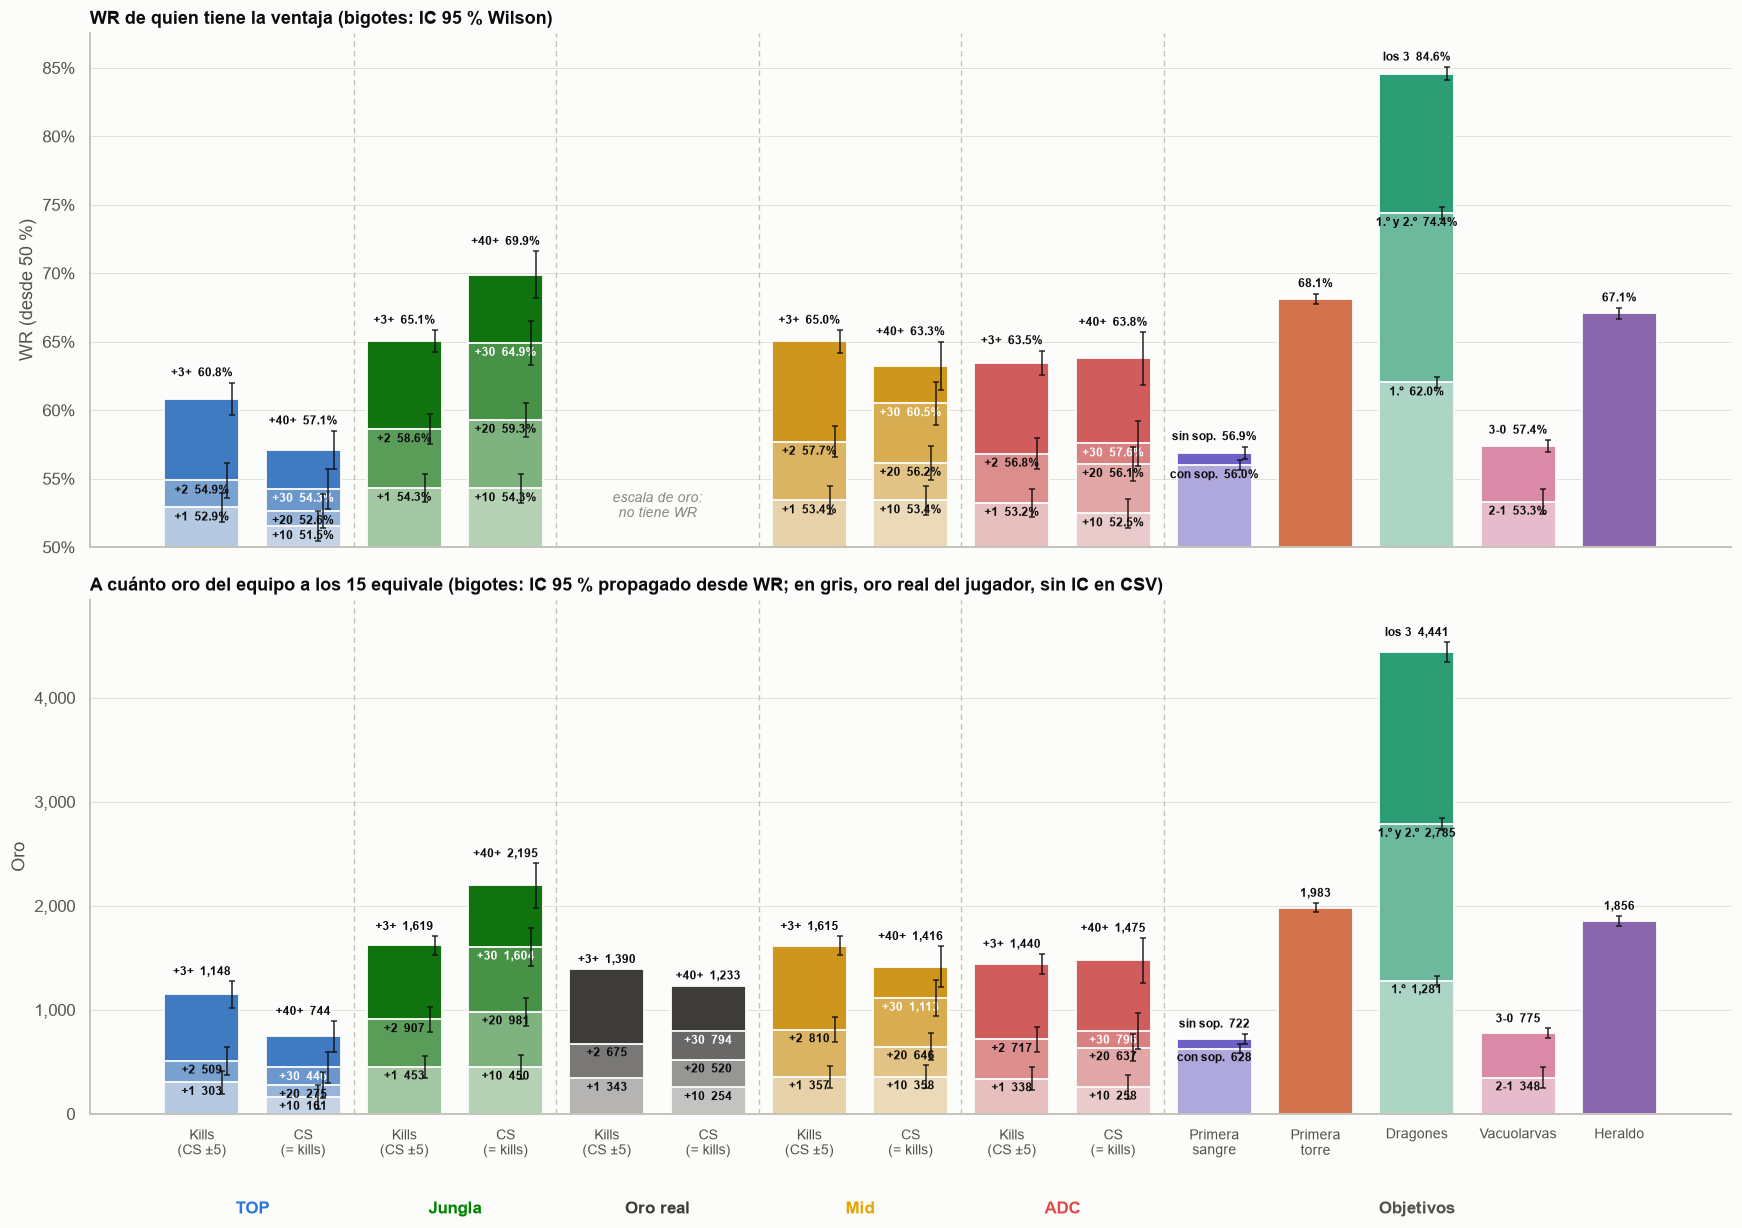

In [9]:
ruta_oro = ROOT / "data" / "analysis" / "oro_equivalente_roles.csv"
if not ruta_oro.exists():
    print("Falta", ruta_oro, "→ correr  python scripts/analysis/oro_equivalente_roles.py")
else:
    from matplotlib.transforms import blended_transform_factory
    oe = pd.read_csv(ruta_oro)
    # "Oro real" (escala en grises, entre jungla y mid): el oro que de verdad tiene de más a los 15 el jugador
    # con esa ventaja, con los 4 roles juntos. No tiene WR.
    ROLES = {"TOP": "TOP", "JUNGLE": "Jungla", "Oro real": "Oro real", "MIDDLE": "Mid", "BOTTOM (ADC)": "ADC"}
    OBJ = {"Primera sangre": ["Primera sangre (con soporte)", "Primera sangre (sin soporte)"],
           "Primera torre": ["Primera torre"],
           "Dragones": ["Primer dragón", "Dos primeros dragones", "Tres primeros dragones"],
           "Vacuolarvas": ["Vacuolarvas 2-1", "Vacuolarvas 3-0"],
           "Heraldo": ["Heraldo"]}
    COLOR = {"TOP": CATEGORICAL[0], "Jungla": CATEGORICAL[5], "Mid": CATEGORICAL[3], "ADC": CATEGORICAL[7],
             "Primera sangre": CATEGORICAL[6], "Primera torre": CATEGORICAL[1], "Dragones": CATEGORICAL[2],
             "Vacuolarvas": CATEGORICAL[4], "Heraldo": "#8a5cb8", "Oro real": "#3d3c39"}
    corto = {"+1 kill": "+1", "+2 kills": "+2", "+3 o más kills": "+3+", "+10 CS": "+10", "+20 CS": "+20",
             "+30 CS": "+30", "+40 o más CS": "+40+", "Primera sangre (con soporte)": "con sop.",
             "Primera sangre (sin soporte)": "sin sop.", "Primer dragón": "1.º", "Dos primeros dragones": "1.º y 2.º",
             "Tres primeros dragones": "los 3", "Vacuolarvas 2-1": "2-1", "Vacuolarvas 3-0": "3-0"}

    # Por rol, dos barras: kills con el CS parejo (|Δ CS| ≤ 5) y CS con las mismas kills (Δ kills = 0)
    VARS = [("kills_cs_parejo", "Kills\n(CS ±5)", "CS ±5"), ("cs_kills_parejas", "CS\n(= kills)", "mismas kills")]
    filas = []   # (barra, bloque, color base, evento, condición, wr, oro, casos)
    for g, rol in ROLES.items():
        for var, nom, cond in VARS:
            for _, r in oe[(oe.grupo == g) & (oe.variable == var)].iterrows():
                filas.append((f"{nom}\n{rol}", rol, rol, r.evento, cond, r["gana quien lo tiene"], r["equivale a"],
                              r.casos))
    piloto = oe[oe.grupo == "piloto"].set_index("evento")
    for obj, evs in OBJ.items():
        for ev in evs:
            r = piloto.loc[ev]
            filas.append((obj.replace(" ", "\n"), "Objetivos", obj, ev, "", r["gana quien lo tiene"],
                          r["equivale a"], r.casos))
    gb = pd.DataFrame(filas, columns=["barra", "bloque", "fam", "evento", "cond", "wr", "oro", "casos"])
    gb["nivel"] = gb.groupby("barra", sort=False).cumcount()
    gb["n"] = gb.groupby("barra", sort=False).evento.transform("size")
    # tono: del claro (nivel más chico) al color pleno (nivel más grande)
    gb["color"] = [sns.light_palette(COLOR[f], n_colors=n + 1)[k + 1] if n > 1 else COLOR[f]
                   for f, n, k in zip(gb.fam, gb.n, gb.nivel)]
    orden = list(dict.fromkeys(gb.barra))
    bloques = list(dict.fromkeys(gb.bloque))
    xs_bloque = {b: [orden.index(x) for x in dict.fromkeys(gb.barra[gb.bloque == b])] for b in bloques}

    fig, axes = plt.subplots(2, 1, figsize=(16, 11.2), sharex=True)
    for ax, col, titulo, fmt in ((axes[0], "wr", "WR de quien tiene la ventaja", "{:.1%}"),
                                 (axes[1], "oro", "A cuánto oro del equipo a los 15 equivale", "{:,.0f}")):
        # de atrás para adelante: primero la capa más alta de cada barra
        rk = gb.groupby("barra", sort=False)[col].rank(ascending=False, method="first")
        gb["capa"] = rk.fillna(gb.n - gb.nivel).astype(int)     # sin WR (oro real): por nivel
        for capa in sorted(gb.capa.unique()):
            d = gb[gb.capa == capa]
            sns.barplot(data=d, x="barra", y=col, order=orden, hue="barra", palette=dict(zip(d.barra, d.color)),
                        width=0.74, edgecolor="#fcfcfb", linewidth=1.2, legend=False, ax=ax)
        paso = 0.003 if col == "wr" else 35
        for _, r in gb.iterrows():
            if pd.isna(r[col]):
                continue
            xi = orden.index(r.barra)
            et = (f"{corto[r.evento]}  " if r.evento in corto else "") + fmt.format(r[col])
            if r.capa == 1:      # la barra de atrás: etiqueta arriba
                ax.text(xi, r[col] + paso, et, ha="center", va="bottom", fontsize=7.8,
                        fontweight="bold", color=INK)
            else:                # las de adelante: adentro, justo debajo de su borde
                claro = r.nivel / max(r.n - 1, 1) < 0.55
                ax.text(xi, r[col] - paso, et, ha="center", va="top", fontsize=7.8,
                        fontweight="bold", color=INK if claro else "white")
        for b in bloques[1:]:    # separadores entre roles y objetivos
            ax.axvline(min(xs_bloque[b]) - 0.5, color="#c3c2b7", lw=0.9, ls=(0, (4, 3)))
        ax.set_title(titulo, loc="left")
        ax.set_xlabel("")
        ax.grid(axis="x", visible=False)
    axes[0].text(np.mean(xs_bloque["Oro real"]), 0.53, "escala de oro:\nno tiene WR", ha="center", va="center",
                 fontsize=9, color=MUTED, style="italic")
    axes[1].set_title("A cuánto oro del equipo a los 15 equivale (en gris, oro real del jugador)", loc="left")
    axes[0].set_ylim(0.5, float(np.nanmax(gb.wr)) + 0.025)
    axes[0].yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
    axes[0].set_ylabel("WR (desde 50 %)")
    axes[1].set_ylim(0, float(gb.oro.max()) * 1.09)
    axes[1].yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:,.0f}"))
    axes[1].set_ylabel("Oro")
    axes[1].set_xticks(range(len(orden)), ["\n".join(b.split("\n")[:-1])
                                           if gb.bloque[gb.barra == b].iloc[0] != "Objetivos" else b for b in orden],
                       fontsize=9)
    tr = blended_transform_factory(axes[1].transData, axes[1].transAxes)
    for b, xs in xs_bloque.items():   # nombre del rol (o "Objetivos") debajo de cada grupo
        axes[1].text(np.mean(xs), -0.17, b, transform=tr, ha="center", va="top", fontsize=11, fontweight="bold",
                     color=COLOR.get(b, INK_2))
    fig.tight_layout()
    plt.show()

**Lectura.**

* *Kills con el CS parejo:* +1 kill vale ~300-450 de oro según el rol y +3 o más ~1.150-1.600. *CS con
  las mismas kills:* +10 CS vale ~160-450 y +40 o más ~750-2.200. Sin la otra ventaja valen bastante menos
  que mirándolas solas (en ADC, +1 kill sola ~470 y +10 CS solos ~540).
* *Escala gris (oro real):* el jugador que va +1 kill con el CS parejo tiene ~340 de oro más que su rival,
  y el que va +10 CS con las mismas kills ~250. El oro equivalente por WR queda **cerca de ese oro real**
  (mid y ADC casi igual, jungla por encima, top por debajo): una kill o unos CS valen, en probabilidad de
  ganar, más o menos el oro que dan.
* **El top es el que menos vale** en las dos (+40 CS: ~740 ± 150) y **el CS de la jungla el que más**
  (+40 CS: ~2.200 ± 210). Entre tramos vecinos o roles parecidos las diferencias suelen quedar dentro del
  IC (por ejemplo, +1 kill: 300-450 con ±105-110).
* *Objetivos* (IC de ±40 a ±100): la primera sangre vale ~630 con soporte y ~720 sin él; las vacuolarvas,
  ~770 si son las 3 y ~350 si quedan 2-1; la primera torre ~1.980 y el heraldo ~1.860. **Los dragones son lo
  que más pesa:** el primero ~1.280, los dos primeros ~2.790 (74 % de WR) y los tres primeros ~4.440 (85 %).
* El heraldo y la mayoría de los dragones caen **después** del minuto 15 (dragón: mediana ~17 min), así
  que en parte miden cómo sigue la partida y no solo el estado a los 15. Las vacuolarvas (~9 min), la
  primera sangre y el 79 % de las primeras torres sí pasan antes.

## 3.2 Las ventajas que se dan vuelta

Qué porcentaje de las partidas pierde el equipo que va adelante en oro, según cuánta ventaja tiene, en
los minutos 10, 15 y 20. Curvas suavizadas: un punto cada 250 de oro, con las partidas que tienen una
ventaja de ±250 alrededor (solo ventanas con 300 partidas o más). Se excluyen las partidas que ya
habían terminado en ese minuto: el frame de la caída del Nexo delataría al ganador.

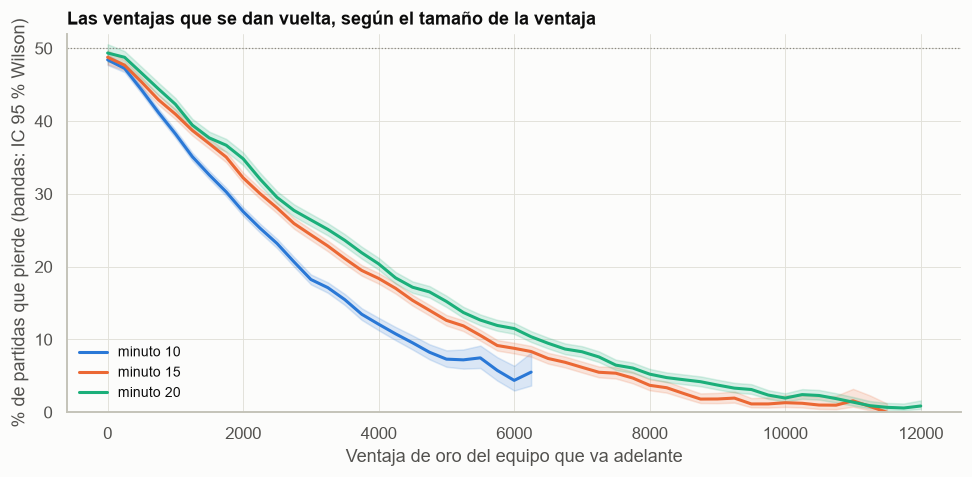

minuto,partidas,% que se da vuelta
10,"186,650",32.5%
15,"185,634",27.0%
20,"171,199",23.7%


Partidas que terminan antes del 20 (rendición): 6.3%. En ellas, el que iba adelante a los 15 gana el 98.7%.


In [10]:
con_tl = ~np.isnan(D["d_gold_15"]) & ~np.isnan(D["d_gold_10"])
filas, resumen = [], []
for m in (10, 15, 20):
    g = D[f"d_gold_{m}"]
    ok = ~np.isnan(g) & (g != 0) & (D["dur_min"] > m)
    ventaja = np.abs(g[ok])
    pierde = np.sign(g[ok]) != np.where(y[ok] == 1, 1, -1)
    resumen.append({"minuto": m, "partidas": int(ok.sum()), "% que se da vuelta": pierde.mean()})
    for c in np.arange(0, 12001, 250):
        w = np.abs(ventaja - c) <= 250
        nw = int(w.sum())
        if nw >= 300:
            pm = float(pierde[w].mean())
            lo_, hi_ = wilson_ci(pm, nw)
            filas.append({"minuto": f"minuto {m}", "ventaja de oro": c, "% que se da vuelta": 100 * pm,
                          "lo": 100 * float(lo_), "hi": 100 * float(hi_)})
vt = pd.DataFrame(filas)
fig, ax = plt.subplots(figsize=(9, 4.5))
for (mom, col) in zip(("minuto 10", "minuto 15", "minuto 20"), CATEGORICAL[:3]):
    dm = vt[vt["minuto"] == mom]
    ax.plot(dm["ventaja de oro"], dm["% que se da vuelta"], color=col, lw=2, label=mom)
    ax.fill_between(dm["ventaja de oro"], dm["lo"], dm["hi"], color=col, alpha=0.16)
ax.axhline(50, color=MUTED, lw=0.8, ls=":")
ax.set_ylim(0, 52)
ax.set_xlabel("Ventaja de oro del equipo que va adelante")
ax.set_ylabel("% de partidas que pierde (bandas: IC 95 % Wilson)")
ax.set_title("Las ventajas que se dan vuelta, según el tamaño de la ventaja", loc="left")
ax.legend(title="", fontsize=9)
plt.tight_layout()
plt.show()
display(pd.DataFrame(resumen).style.format({"partidas": "{:,}", "% que se da vuelta": "{:.1%}"})
        .hide(axis="index").set_caption("En total, partidas que pierde el que va adelante"))
sin20 = con_tl & np.isnan(D["d_gold_20"])
print(f"Partidas que terminan antes del 20 (rendición): {sin20.sum() / con_tl.sum():.1%}. "
      f"En ellas, el que iba adelante a los 15 gana el "
      f"{(np.sign(D['d_gold_15'][sin20]) == np.where(y[sin20] == 1, 1, -1)).mean():.1%}.")

**Lectura.**

* Con una ventaja chica la partida sigue abierta: cerca de 0 el que va adelante pierde casi la mitad.
  La probabilidad de que se dé vuelta cae casi en línea recta hasta los 4.000-5.000 de oro y después
  se aplana.
* **La misma ventaja pesa más cuanto antes se consigue.** Con 2.000 de oro de ventaja, el que va
  adelante pierde ~28 % de las veces al minuto 10, ~32 % al 15 y ~35 % al 20: a los 10 minutos esa
  ventaja es una porción mucho mayor del oro total que hay en juego.
* Al 20, aun con 6.000 de oro de ventaja, se da vuelta 1 de cada 10 partidas. Por debajo del 2 % hace
  falta más de 9.000.
* Las rendiciones antes del 20 son lo contrario: ahí casi siempre gana el que iba adelante.

Es el techo práctico de cualquier modelo previo: aunque supiera exactamente cómo va a estar la
partida a los 10 minutos, seguiría equivocándose en 3 de cada 10.

## 3.3 Lo que el oro no dice: objetivos y eventos del timeline

El dataset guardó del timeline solo oro total, XP, nivel, CS, daño y K/D/A a los 10/15/20. Para medir
qué agregan los **eventos** se están bajando de nuevo los timelines completos de toda la base
(`timelines_eventos.py --todas`, PROJECT_SUMMARY §9.S.64). Al 18/11 hay 62.706: **toda V Master+ (16.428)**
y 46.278 partidas de Master+ del ajuste (antes era un piloto de 8.000 + 8.000). Con ellos se armaron, con
solo lo ocurrido antes del minuto:

* **Objetivos y estado instantáneo:** dragones y punto de alma, larvas, Heraldo, torres por nivel,
  placas, inhibidores, oro sin gastar y oro invertido (total − sin gastar), quién está muerto en ese
  minuto y shutdowns cobrados.
* **Tiempos y momentum:** primera sangre y primera torre (lado y minuto), kills y oro de los últimos
  3 minutos, wards colocados y destruidos.

Se suman en una segunda etapa sobre la logística en vivo (8 estadísticas + trayectorias +
expectativas), ajustada con el resto del entrenamiento (las Master+ sin timeline completo, ~48.000); la
segunda etapa se ajusta con las 46.278 del ajuste que sí lo tienen y se mide en toda V
(`ingame_eventos.py`). Son las mismas partidas para la base y para la versión con eventos.

minuto,AUC base,AUC + eventos,Δ AUC,IC 95 %,Accuracy base,Accuracy + eventos,Δ Accuracy,tramos que mejora
10,0.7872,0.7928,+0.0055,[+0.0039; +0.0073],71.4%,71.8%,+0.3%,3/3
15,0.8408,0.8468,+0.0060,[+0.0046; +0.0075],75.9%,76.2%,+0.3%,3/3
20,0.8726,0.8795,+0.0070,[+0.0054; +0.0084],78.7%,79.3%,+0.6%,3/3


Partidas: muestra de entrenamiento 42,182-46,018, V 14,971-16,331 (según el minuto; solo las que siguen vivas). Sumar además tiempos, momentum y wards (prioridad 2): Δ AUC 10: +0.0000, 15: +0.0002, 20: +0.0004.


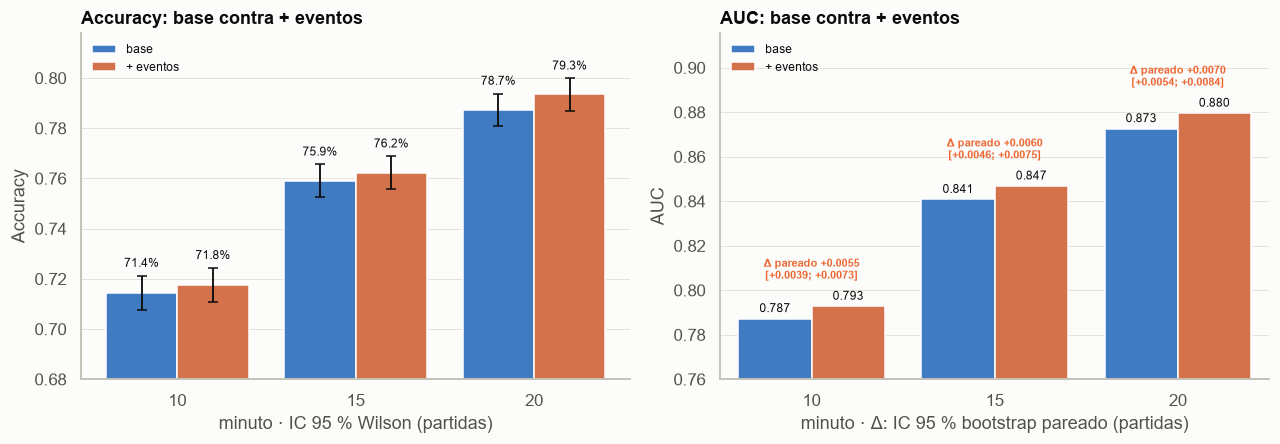

In [11]:
# V Master+, de data/analysis/ingame/eventos/eventos_aporte.csv (python scripts/analysis/ingame_eventos.py)
evr = pd.read_csv(ROOT / "data" / "analysis" / "ingame" / "eventos" / "eventos_aporte.csv")
b_ = evr[evr.variante.str.startswith("base")].set_index("minuto")
e_ = evr[evr.variante.str.startswith("+ prioridad 1 (")].set_index("minuto")
e2 = evr[evr.variante.str.startswith("+ prioridad 1 + 2")].set_index("minuto")
ev = pd.DataFrame({
    "minuto": b_.index, "AUC base": b_["AUC V"].to_numpy(), "AUC + eventos": e_["AUC V"].to_numpy(),
    "Accuracy base": b_["Accuracy V"].to_numpy(), "Accuracy + eventos": e_["Accuracy V"].to_numpy(),
})
ev["Δ AUC"] = ev["AUC + eventos"] - ev["AUC base"]
ev["IC 95 %"] = [f"[{lo:+.4f}; {hi:+.4f}]" for lo, hi in zip(e_["Δ V lo"], e_["Δ V hi"])]
ev["Δ Accuracy"] = ev["Accuracy + eventos"] - ev["Accuracy base"]
ev["tramos que mejora"] = [f"{k}/3" for k in e_["bloques que mejora"]]
ev = ev[["minuto", "AUC base", "AUC + eventos", "Δ AUC", "IC 95 %", "Accuracy base", "Accuracy + eventos",
         "Δ Accuracy", "tramos que mejora"]]
display(ev.style.format({"AUC base": "{:.4f}", "AUC + eventos": "{:.4f}", "Δ AUC": "{:+.4f}",
                         "Accuracy base": "{:.1%}", "Accuracy + eventos": "{:.1%}", "Δ Accuracy": "{:+.1%}"})
        .hide(axis="index").set_caption(f"Objetivos y estado instantáneo sobre la logística en vivo "
                                        f"(ajuste {int(e_['n_train'].iloc[0]):,}, V Master+ {int(e_['n_V'].iloc[0]):,})"))
print(f"Partidas: muestra de entrenamiento {int(e_['n_train'].min()):,}-{int(e_['n_train'].max()):,}, "
      f"V {int(e_['n_V'].min()):,}-{int(e_['n_V'].max()):,} (según el minuto; solo las que siguen vivas). "
      "Sumar además tiempos, momentum y wards (prioridad 2): Δ AUC "
      + ", ".join(f"{m}: {d:+.4f}" for m, d in zip(e2.index, e2["AUC V"] - e_["AUC V"])) + ".")

fig, axes = plt.subplots(1, 2, figsize=(11.8, 4.2))
_n_ev = b_["n_V"].to_dict()
for ax, met in zip(axes, ("Accuracy", "AUC")):
    s = ev.melt(id_vars="minuto", value_vars=[f"{met} base", f"{met} + eventos"], var_name="modelo", value_name=met)
    s["modelo"] = s["modelo"].str.replace(f"{met} ", "", regex=False)
    sns.barplot(data=s, x="minuto", y=met, hue="modelo", palette=CATEGORICAL[:2], ax=ax)
    lo = 0.68 if met == "Accuracy" else 0.76
    hi_top = 0.0
    for cont, mod_lbl in zip(ax.containers, ("base", "+ eventos")):
        for bar, m_val in zip(cont, ev["minuto"]):
            valor_barra = bar.get_height()
            nm_ = float(_n_ev[m_val])
            xc = bar.get_x() + bar.get_width() / 2
            tope = valor_barra
            if met == "Accuracy":
                ci_l, ci_h = wilson_ci(valor_barra, nm_)
                tope = float(ci_h)
                ax.errorbar(xc, valor_barra,
                            yerr=[[max(0.0, valor_barra - ci_l)], [max(0.0, ci_h - valor_barra)]],
                            fmt="none", ecolor=INK, elinewidth=1.2, capsize=3.5, zorder=5)
            ax.text(xc, tope + (0.0025 if met == "Accuracy" else 0.0018),
                    f"{valor_barra:.1%}" if met == "Accuracy" else f"{valor_barra:.3f}",
                    ha="center", va="bottom", fontsize=7.8, color=INK)
            hi_top = max(hi_top, tope)
    ax.set_ylim(lo, hi_top + (0.018 if met == "Accuracy" else 0.012))
    ax.set_xlabel("minuto · IC 95 % Wilson (partidas)" if met == "Accuracy" else "minuto")
    ax.set_title(f"{met}: base contra + eventos", loc="left")
    ax.legend(title="", fontsize=8, loc="upper left")
plt.tight_layout()
plt.show()

**Lectura.**

* Con 4 veces más partidas el resultado del piloto se confirma: **+0,0055 de AUC al 10, +0,0060 al 15 y
  +0,0070 al 20** en toda V Master+, todas con el IC por bootstrap pareado entero arriba de 0, y mejora
  en los 3 tramos por fecha de la muestra en los tres minutos. En accuracy suma +0,3 a +0,6 puntos. Es
  la mayor mejora del modelo en vivo desde §9.S.52. Con el piloto (8.000 + 8.000) daba lo mismo, con el
  doble de margen.
* Lo que más pesa: **los dragones** (en los tres minutos, y cada vez más), **la primera sangre** (de qué
  lado y cuándo, sobre todo al 15), el **oro sin gastar contra el invertido** y **quién está muerto** en
  ese minuto; al 10 también las larvas. Los tiempos, el momentum y los wards suman ≤ 0,0004.
* Es menos de lo que se podría esperar: torres, placas y kills ya están en el oro. Lo que suma es lo
  que el oro no refleja (los buffs de los dragones, el punto de alma, el poder comprado y los muertos
  en el momento).
* La base acá es más floja que la logística en vivo completa (0,787 contra 0,790 al 10), porque se ajusta
  sin las partidas que tienen timeline completo.
* Está medido sobre la logística en vivo, no sobre el ensamble vigente, y con el 23 % de la base. Para
  el número final falta terminar la descarga (quedan ~210.000 partidas) y entrar los eventos al
  modelo en vivo vigente.

# 4. Qué familias de variables pesan

Dentro del escalón 9 se saca una familia por vez y se reentrena: lo que se pierde es lo que esa
familia aporta **además** de las demás. La segunda columna es lo que predice **sola**. El draft
(campeón × línea) entra como una familia más.

In [12]:
FAMILIAS_XD = {
    "Margen acumulado": ("Jugadores", lambda c: c.startswith("acum_")),
    "Margen (últimas 20)": ("Jugadores", lambda c: c.startswith("v20_")),
    "WR de sesión": ("Jugadores", lambda c: c in ("wr_acum", "wr_v20")),
    "Rol Mastery": ("Jugadores", lambda c: c in ("logn_tot", "share_lane", "offrole")),
    "Pool": ("Jugadores", lambda c: c in ("conc_rec", "conc_ant", "d_pool", "otp_nuevo")),
    "Ritmo y descanso": ("Jugadores", lambda c: c in ("ritmo", "log_horas_desde")),
    "Champion Mastery": ("Jugador × campeón", lambda c: c in JUGADOR_CAMPEON),
    "Champion Stats": ("Campeones", lambda c: c.startswith(("tag_", "info_", "st_"))),
    "Champion Style": ("Campeones", lambda c: c.startswith("perf_")),
}
fam_de = {c: next((f for f, (_, g) in FAMILIAS_XD.items() if g(c)), None) for c in cols}
assert all(fam_de.values()), [c for c, f in fam_de.items() if f is None]
# familia de cada columna de XALL
fam_col = np.concatenate([["Draft (campeón × línea)"] * nd, np.tile(np.array([fam_de[c] for c in cols]), 5), fam9])
FAMILIAS = {"Draft (campeón × línea)": "Campeones"} | {f: b for f, (b, _) in FAMILIAS_XD.items()} \
           | {f: b for f, b, _ in PARTES9}
assert set(FAMILIAS) == set(fam_col)

a_todo = roc_auc_score(yv, P9)
filas = []
for f, bl in FAMILIAS.items():
    dlt, lo, hi = diferencia(logistica(fam_col != f), P9)
    p_sola = logistica(fam_col == f)
    filas.append({"familia": f, "bloque": bl, "columnas": int((fam_col == f).sum()),
                  "Δ al sacarla": dlt, "_hi": hi,
                  "AUC sola": roc_auc_score(yv, p_sola)})
fam = pd.DataFrame(filas).sort_values("Δ al sacarla").reset_index(drop=True)
fam["significativa"] = fam.pop("_hi") < 0       # el IC 95 % del Δ queda entero debajo de 0
print(f"Escalón 9 completo: AUC {a_todo:.4f}")
display(fam.style.format({"Δ al sacarla": "{:+.4f}", "AUC sola": "{:.4f}"})
        .hide(axis="index").set_caption("Aporte de cada familia")
        .highlight_min(subset=["Δ al sacarla"], props=RESALTE).highlight_max(subset=["AUC sola"], props=RESALTE))

Escalón 9 completo: AUC 0.6740


familia,bloque,columnas,Δ al sacarla,AUC sola,significativa
Champion Mastery,Jugador × campeón,20,-0.0068,0.5773,True
Pool,Jugadores,20,-0.0031,0.5195,True
Draft (campeón × línea),Campeones,851,-0.0026,0.5490,True
Nivel histórico,Jugadores,3,-0.0025,0.5189,True
Duelo esperado,Campeones,12,-0.0019,0.5259,True
W/L de la foto,Jugadores,4,-0.0015,0.5514,True
Kalman-Elo,Jugadores,19,-0.0010,0.5592,True
Modelo por línea,Mixto,6,-0.0010,0.6016,True
Ritmo y descanso,Jugadores,10,-0.0010,0.5209,True
Margen jugador-campeón,Jugador × campeón,75,-0.0010,0.5811,False


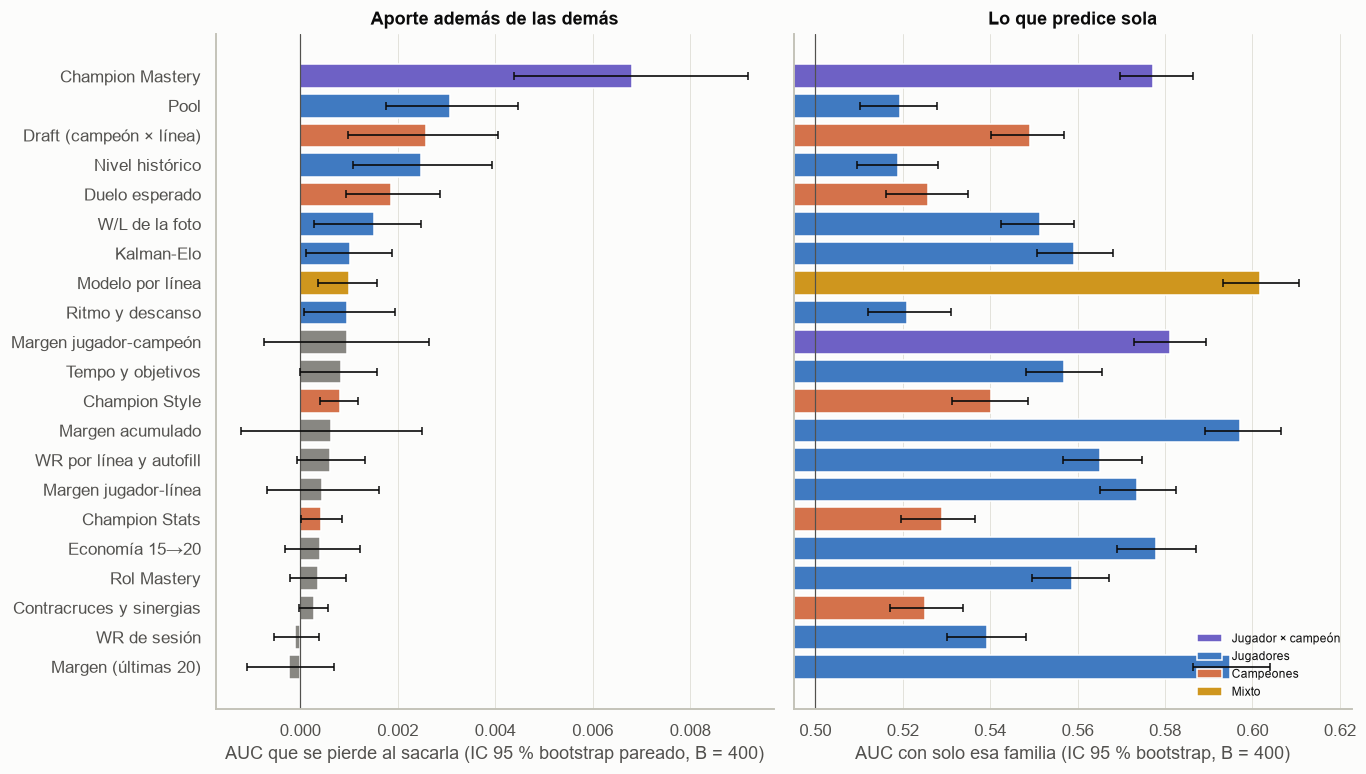

In [13]:
fig, ax = plt.subplots(1, 2, figsize=(12.6, 7.2), sharey=True)
f4 = fam.assign(pierde=-fam["Δ al sacarla"],
                color=np.where(fam.significativa, fam.bloque, "no significativo"))
sns.barplot(data=f4, x="pierde", y="familia", hue="color", palette=COLOR_BLOQUE | SIG, dodge=False,
            legend=False, ax=ax[0])
ax[0].axvline(0, color=INK_2, lw=0.8)
ax[0].set_ylabel("")
ax[0].set_xlabel("AUC que se pierde al sacarla")
ax[0].set_title("Aporte además de las demás")
sns.barplot(data=fam, x="AUC sola", y="familia", hue="bloque", palette=COLOR_BLOQUE, dodge=False, ax=ax[1])
ax[1].set_xlim(0.495, fam["AUC sola"].max() + 0.012)
ax[1].axvline(0.5, color=INK_2, lw=0.8)
ax[1].set_xlabel("AUC con solo esa familia")
ax[1].set_title("Lo que predice sola")
ax[1].legend(fontsize=8, loc="lower right", title="")
plt.tight_layout()
plt.show()

* **Champion Mastery sigue siendo lo que no se puede reemplazar**: sacarla cuesta −0,0068, más del
  doble que cualquier otra familia, porque ninguna otra sabe si el jugador estrena el campeón. En el
  híbrido costaba −0,019: el margen jugador-campeón del escalón 9 cubre una parte.
* Después vienen el **pool** (−0,0029), el **nivel histórico** (−0,0024), el **draft** (−0,0024), el
  **duelo esperado** (−0,0018) y el **W/L de la foto** (−0,0014): cada una sabe algo que ninguna
  otra tiene.
* **Las familias de margen se tapan entre sí.** Son de lo que más predice solo (modelo por línea 0,602,
  margen acumulado 0,597, últimas 20 0,595), pero sacar cualquiera cuesta ≤ 0,001, porque el
  margen acumulado, el de las últimas 20, el jugador-línea, el jugador-campeón y el Kalman-Elo miden
  casi lo mismo: cuánto mejor que lo esperado viene rindiendo el jugador.
* **El WR de sesión y el margen de las últimas 20 sobran** (sacarlas da +0,0002 y +0,0003): con el
  resto adentro son una versión más ruidosa de lo mismo.
* El pool aporta aunque solo prediga casi nada (0,520): modula a las demás. Un especialista con su
  campeón no es lo mismo que alguien que rota.

# 5. Dónde falla

Con el escalón 9 de la sección 2, en V Master+.

* **Tier del lobby:** media del tier de los 10 (Diamond = 0, Master = 1, GM = 2, Challenger = 3).
  V Master+ ya exige que la mediana del lobby sea Master o más, así que no hay lobbies Diamond: los
  de tier medio < 1 son lobbies de Master con algunos Diamond mezclados.
* **Historial mínimo:** el jugador del lobby con menos partidas previas en el dataset.

In [14]:
pv = P9
tl = np.nanmean(tnum[val], axis=1)
nmin = np.expm1(Xj[val][:, :, :, cols.index("logn_tot")].reshape(len(yv), 10).min(1))
grupos = {
    "Lobby con Diamond mezclados (tier medio < 1)": tl < 1,
    "Lobby Master (1 a 1,5)": (tl >= 1) & (tl < 1.5),
    "Lobby GM+ (≥ 1,5)": tl >= 1.5,
    "Historial mínimo < 10 partidas": nmin < 10,
    "Historial mínimo 10 a 49": (nmin >= 10) & (nmin < 50),
    "Historial mínimo ≥ 50": nmin >= 50,
}
filas = []
for g, mm in grupos.items():
    if mm.sum() < 300:          # grupo sin volumen en V Master+
        continue
    filas.append({"grupo": g, "partidas": int(mm.sum()), "AUC": roc_auc_score(yv[mm], pv[mm]),
                  "acierto": ((pv[mm] > 0.5) == yv[mm]).mean(), "gana azul": yv[mm].mean()})
display(pd.DataFrame(filas).style.format({"AUC": "{:.3f}", "acierto": "{:.1%}", "gana azul": "{:.1%}"})
        .hide(axis="index").set_caption("Rendimiento por grupo (V)"))

grupo,partidas,AUC,acierto,gana azul
Lobby con Diamond mezclados (tier medio < 1),11502,0.673,62.5%,48.5%
"Lobby Master (1 a 1,5)",3783,0.675,62.6%,45.4%
"Lobby GM+ (≥ 1,5)",1143,0.679,62.9%,48.3%
Historial mínimo < 10 partidas,2452,0.678,63.5%,47.0%
Historial mínimo 10 a 49,9522,0.678,62.8%,48.3%
Historial mínimo ≥ 50,4454,0.663,61.6%,47.2%


En V Master+ el escalón 9 rinde parejo en todos los grupos (AUC 0,673-0,679, acierto 62,5-62,6 % por
tier). Los lobbies con Diamond mezclados ya no son más difíciles: el modelo se entrena solo con Master+
y el nivel histórico y el W/L de la foto ubican a cada jugador. Lo único que se separa es que **todos**
tengan mucho historial (≥ 50 partidas el que menos tiene: 0,663 / 61,5 %). Esos lobbies son los más
parejos (jugadores estables, emparejados entre sí por un MMR ya asentado), así que hay menos diferencia
que detectar.

## 5.1 Accuracy según el LP medio del lobby

Curva suavizada (ventana de ±50 LP, un punto cada 25 LP; solo ventanas con 300 partidas o más) con el
escalón 9, entrenado solo con Master+ anterior al 16/09. Dos conjuntos, nunca usados para entrenar
ni para elegir nada:

* **V Master+:** la evaluación oficial (mediana del tier del lobby ≥ Master).
* **Diamond-V:** las partidas Diamond de la misma ventana, apartadas como chequeo a ciegas. El modelo
  las predice fuera de su población de entrenamiento.

LP en escala absoluta (Diamond IV 0 LP = 0, Master 0 LP = 400). Cortes de la foto 2 (28/10):
Grandmaster 1.132 y Challenger 1.660 (en la foto 1, 1.045 y 1.589). Las curvas salen de
`scripts/analysis/acierto_por_lp_duracion.py --modelo escalon9`.

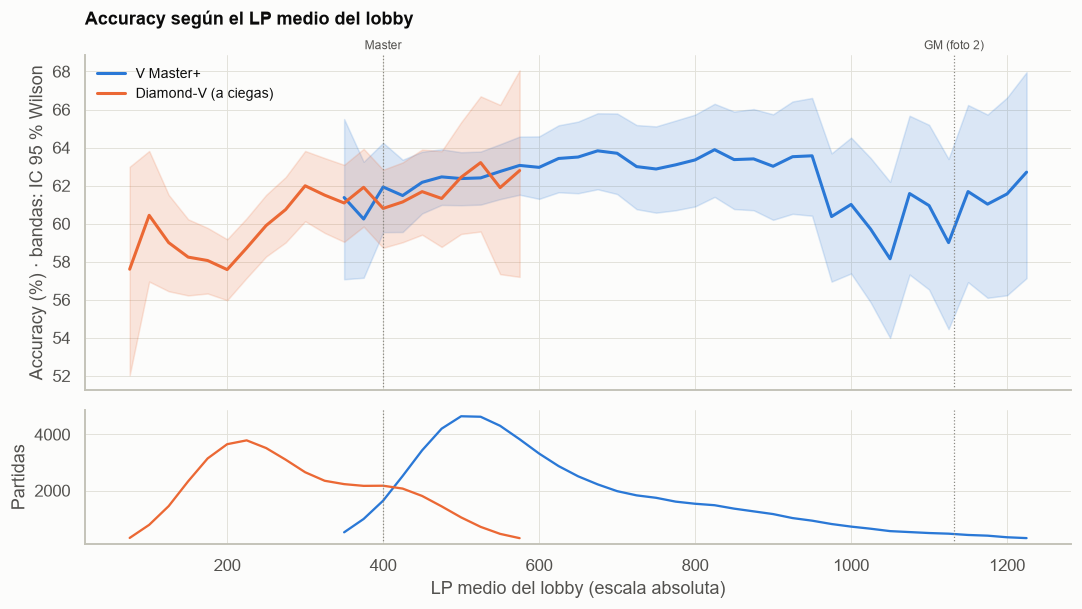

In [15]:
ruta_curvas = ROOT / "data" / "analysis" / "figuras" / "acierto_lp_duracion_escalon9.csv"
if not ruta_curvas.exists():
    print("Falta", ruta_curvas, "→ correr  python scripts/analysis/acierto_por_lp_duracion.py --modelo escalon9")
else:
    curvas = pd.read_csv(ruta_curvas)

    def dibujar(ejes, xlabel, titulo, marcas=()):
        fig, (a1, a2) = plt.subplots(2, 1, figsize=(10, 5.7), sharex=True, gridspec_kw={"height_ratios": [3, 1.2]})
        for (eje, nombre), color in zip(ejes.items(), CATEGORICAL):
            d = curvas[curvas.eje == eje].sort_values("x")
            lo_w, hi_w = wilson_ci(d["acc"].to_numpy() / 100.0, d["n"].to_numpy())
            a1.plot(d.x, d.acc, color=color, lw=2, label=nombre)
            a1.fill_between(d.x, 100.0 * lo_w, 100.0 * hi_w, color=color, alpha=0.16)
            a2.plot(d.x, d.n, color=color, lw=1.5)
        for xv, txt in marcas:
            for a in (a1, a2):
                a.axvline(xv, color=MUTED, lw=0.8, ls=":")
            a1.text(xv, 1.01, txt, transform=a1.get_xaxis_transform(), ha="center", va="bottom", fontsize=8, color=INK_2)
        a1.set_ylabel("Accuracy (%) · bandas: IC 95 % Wilson")
        a1.set_xlabel("")
        a2.set_ylabel("Partidas")
        a2.set_xlabel(xlabel)
        a1.set_title(titulo, loc="left", pad=20 if marcas else 6)
        a1.legend(fontsize=9)
        plt.tight_layout()
        plt.show()

    dibujar({"lp_master": "V Master+", "lp_diamond": "Diamond-V (a ciegas)"},
            "LP medio del lobby (escala absoluta)", "Accuracy según el LP medio del lobby",
            marcas=((400, "Master"), (1132, "GM (foto 2)")))

**Lectura.** En V Master+ el modelo rinde parejo a lo largo de todo el LP, entre 61 y 63,5 %, con el
pico en Master alto (~650 LP). Arriba de ~1.000 la curva baja a 58-61 %, pero ahí hay entre 300 y 600
partidas por ventana (±2-3 puntos de error), así que es ruido. No hay lobbies con promedio de
Challenger con volumen: cada lobby se mezcla con Masters y el promedio más alto con datos ronda los
1.200 (nivel GM). En Diamond-V el modelo da 58 % en Diamond bajo y sube a 61-63 % cerca de Master. No
es por ser Diamond: en esos lobbies casi no hay historial de los jugadores (mediana de 4 partidas
previas en el jugador con menos), y el modelo nunca vio esa población (§9.S.52:
`scripts/analysis/diamante_conocidos.py`).

## 5.2 Accuracy según la duración de la partida

Misma curva con ventana de ±1 minuto. La duración se conoce recién al final: esto es descriptivo y el
modelo no la usa.

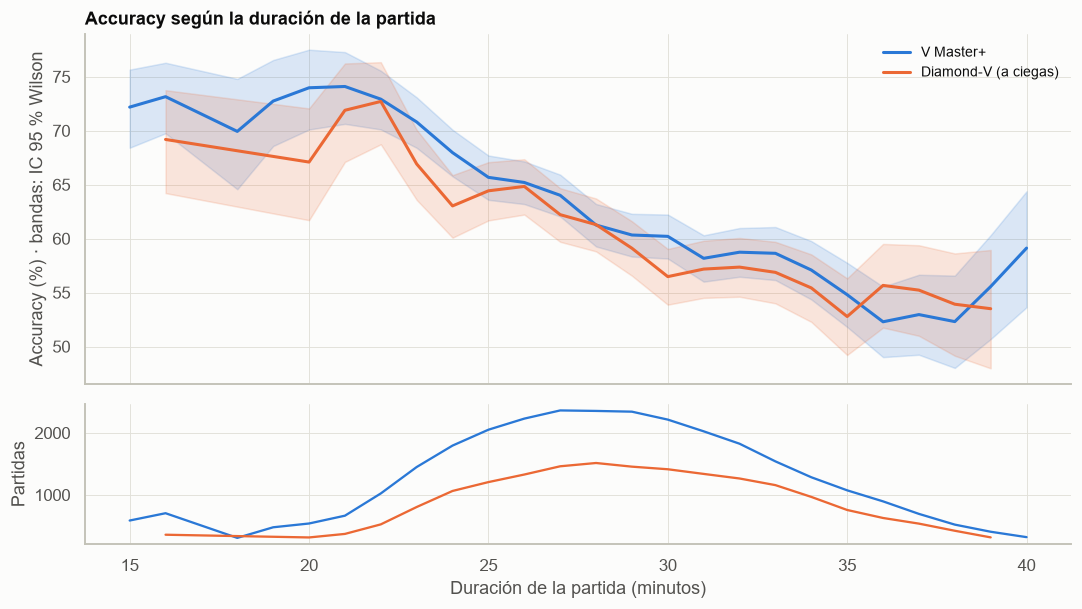

In [16]:
if ruta_curvas.exists():
    dibujar({"dur_master": "V Master+", "dur_diamond": "Diamond-V (a ciegas)"},
            "Duración de la partida (minutos)", "Accuracy según la duración de la partida")

**Lectura.** Las partidas cortas son mucho más predecibles: entre 15 y 22 minutos el modelo acierta
72-74 % en Master+. Desde el minuto 22 cae casi en línea recta, hasta 60 % a los 30 minutos y 52-55 %
desde los 35. Una partida corta suele terminar en rendición porque un equipo era claramente más fuerte,
y esa diferencia el modelo la ve antes de empezar. Las largas son las parejas, que se deciden por
peleas y objetivos tardíos, y antes de la partida eso es casi una moneda al aire. Diamond y Master+
se parecen mucho desde los 23 minutos: la diferencia entre las dos ligas está casi toda en las
partidas cortas.

# 6. Partidas fáciles y difíciles de predecir

¿Qué cosas pesan cuando la partida es fácil de predecir y cuáles cuando es difícil?

**Definición.** La dificultad se mide con el propio escalón 9 de la sección 2:
*fácil* = el 20 % de las partidas de V donde está más seguro (|logit| más grande), *difícil* = el
20 % donde está más cerca del 50 %, *medio* = el resto.

**Descomposición.** En una logística, el logit es exactamente la suma de lo que aporta cada
variable: $\text{logit} = b + \sum_f c_f$, con $c_f = \sum_{j \in f} w_j x_j$ para cada familia
$f$. Así se puede ver, partida por partida, qué familia empujó la predicción y hacia dónde. El
**aporte alineado** es $c_f \cdot \operatorname{signo}(\text{logit})$: positivo si la familia
empuja hacia el equipo que el modelo elige, negativo si empuja en contra.

In [17]:
def aportes(X, w):
    # aporte de cada familia al logit: c_f = Σ_{j ∈ f} w_j x_j
    return pd.DataFrame({f: np.asarray(X[:, fam_col == f] @ w[fam_col == f]).ravel() for f in FAMILIAS})


w = lr9.coef_[0]
Cf = aportes(X_val, w)
logit_v = lr9.intercept_[0] + Cf.sum(axis=1).to_numpy()
assert np.allclose(1 / (1 + np.exp(-logit_v)), P9, atol=1e-6)

conf = np.abs(logit_v)
GR = ["difícil", "medio", "fácil"]
grupo = pd.Series(pd.qcut(conf, [0, 0.2, 0.8, 1], labels=GR), name="grupo")
fac = (grupo == "fácil").to_numpy()
fav_azul = logit_v > 0
acerto = fav_azul == (yv == 1)
alin = Cf.mul(np.sign(logit_v), axis=0)
conflicto = 1 - np.abs(Cf.sum(axis=1)) / Cf.abs().sum(axis=1)

res7 = pd.DataFrame({
    "partidas": grupo.value_counts().reindex(GR),
    "prob. del favorito (media)": pd.Series(1 / (1 + np.exp(-conf))).groupby(grupo, observed=False).mean(),
    "acierto": pd.Series(acerto).groupby(grupo, observed=False).mean(),
    "conflicto entre familias": conflicto.groupby(grupo, observed=False).mean(),
    f"familias a favor (de {len(FAMILIAS)})": (alin > 0).sum(axis=1).groupby(grupo, observed=False).mean(),
})
display(res7.style.format({"prob. del favorito (media)": "{:.1%}", "acierto": "{:.1%}",
                           "conflicto entre familias": "{:.2f}", f"familias a favor (de {len(FAMILIAS)})": "{:.1f}"})
        .set_caption("Los tres grupos (V)"))
print("Conflicto = 1 − |Σ c_f| / Σ |c_f|: 0 si todas las familias empujan hacia el mismo lado, "
      "cerca de 1 si se cancelan.")

,partidas,prob. del favorito (media),acierto,conflicto entre familias,familias a favor (de 21)
grupo,,,,,
difícil,3286,52.1%,52.3%,0.95,10.7
medio,9856,61.9%,61.4%,0.81,11.6
fácil,3286,77.2%,76.4%,0.57,13.1


Conflicto = 1 − |Σ c_f| / Σ |c_f|: 0 si todas las familias empujan hacia el mismo lado, cerca de 1 si se cancelan.


**Calibración y confianza.** Izquierda: si las probabilidades del escalón 9 son honestas (por
deciles). Derecha: el acierto si solo se predicen las partidas más claras; el 20 % de la izquierda
del eje son las *fáciles* y el 100 % es todo V.

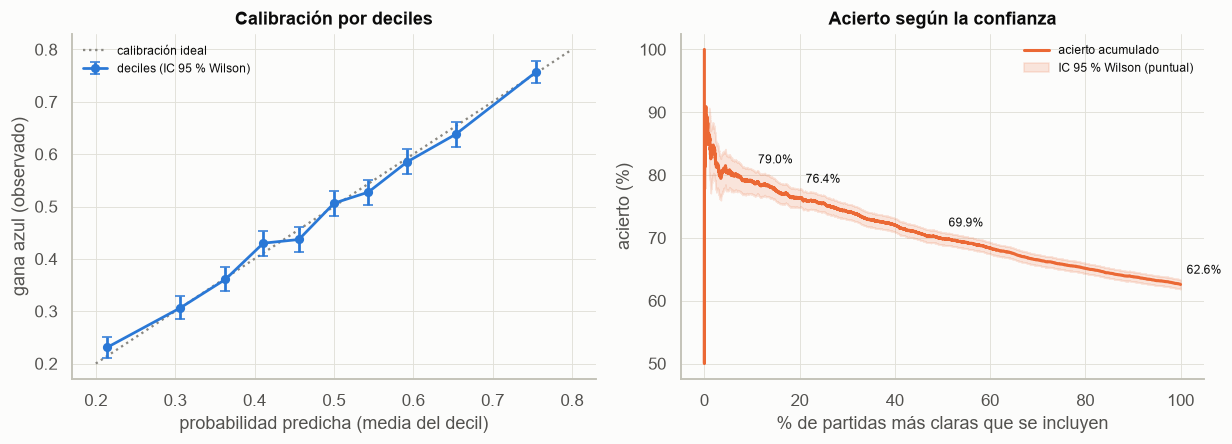

ECE por deciles: 0.0104


In [18]:
p_h = P9
fig, ax = plt.subplots(1, 2, figsize=(11.4, 4.2))
q = pd.qcut(p_h, 10, labels=False, duplicates="drop")
cal = pd.DataFrame({"p": p_h, "y": yv, "q": q}).groupby("q").agg(p=("p", "mean"), y=("y", "mean"), n=("y", "size"))
lo_c, hi_c = wilson_ci(cal["y"].to_numpy(), cal["n"].to_numpy())
ax[0].plot([0.2, 0.8], [0.2, 0.8], color=MUTED, ls=":", label="calibración ideal")
ax[0].plot(cal["p"], cal["y"], marker="o", color=CATEGORICAL[0], lw=1.8, ms=5, label="deciles (IC 95 % Wilson)")
ax[0].fill_between(cal["p"], lo_c, hi_c, color=CATEGORICAL[0], alpha=0.16, lw=0)
ax[0].set_xlabel("probabilidad predicha (media del decil)")
ax[0].set_ylabel("gana azul (observado)")
ax[0].set_title("Calibración por deciles")
ax[0].legend(fontsize=8, loc="upper left")

o = np.argsort(-np.abs(p_h - 0.5))
k_seq = np.arange(1, len(o) + 1)
acc_c = np.cumsum((p_h[o] > 0.5) == yv[o]) / k_seq
cob = k_seq / len(o)
lo_a, hi_a = wilson_ci(acc_c, k_seq)
m_cov = cob >= 0.01                                         # desde 1 % de cobertura (n ≥ 164) para no distorsionar la escala
ax[1].plot(cob * 100, acc_c * 100, color=CATEGORICAL[1], lw=2, label="acierto acumulado")
ax[1].fill_between(cob[m_cov] * 100, lo_a[m_cov] * 100, hi_a[m_cov] * 100,
                   color=CATEGORICAL[1], alpha=0.16, label="IC 95 % Wilson (puntual)")
for c in (0.1, 0.2, 0.5, 1.0):
    i = int(c * len(o)) - 1
    ax[1].annotate(f"{acc_c[i]:.1%}", (c * 100, hi_a[i] * 100), xytext=(4, 4), textcoords="offset points", fontsize=8)
ax[1].set_xlabel("% de partidas más claras que se incluyen")
ax[1].set_ylabel("acierto (%)")
ax[1].set_title("Acierto según la confianza")
ax[1].legend(fontsize=8, loc="upper right")
plt.tight_layout()
plt.show()
ece = np.average(np.abs(cal.p - cal.y), weights=cal.n)
print(f"ECE por deciles: {ece:.4f}")

## 6.1 Qué empuja la predicción en cada grupo

Izquierda: aporte alineado medio de cada familia (cuánto empuja hacia el favorito). Derecha:
tamaño del aporte sin importar el signo, $|c_f|$: cuánto se mueve esa familia en ese grupo,
aunque se cancele con otras.

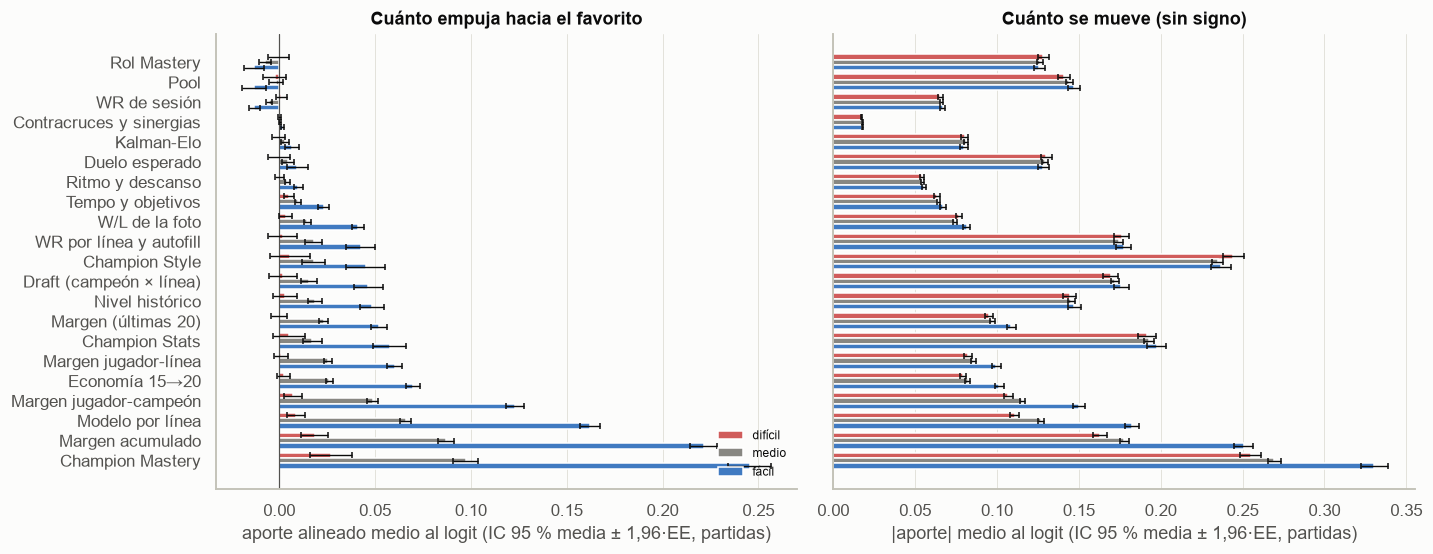

In [19]:
A = alin.groupby(grupo, observed=False).mean().T[GR]
M = Cf.abs().groupby(grupo, observed=False).mean().T[GR]
# fuera las familias que casi no empujan en ningún grupo (|aporte alineado medio| < 0,01 en los tres)
chicas = A.index[(A.abs() < 0.01).all(axis=1)]
A, M = A.drop(chicas), M.drop(chicas)
orden = A["fácil"].sort_values().index
fig, ax = plt.subplots(1, 2, figsize=(13.2, 5.2), sharey=True)
colg = {"difícil": CATEGORICAL[7], "medio": MUTED, "fácil": CATEGORICAL[0]}
for a, tabla_g in zip(ax, (A, M)):
    lg_ = tabla_g.loc[orden].rename_axis("familia").reset_index().melt(id_vars="familia", var_name="grupo", value_name="v")
    sns.barplot(data=lg_, x="v", y="familia", hue="grupo", hue_order=GR, palette=colg, order=list(orden), ax=a)
    a.set_ylabel("")
ax[0].axvline(0, color=INK_2, lw=0.8)
ax[0].set_xlabel("aporte alineado medio al logit")
ax[0].set_title("Cuánto empuja hacia el favorito")
ax[1].set_xlabel("|aporte| medio al logit")
ax[1].set_title("Cuánto se mueve (sin signo)")
ax[0].legend(fontsize=8, loc="lower right", title="")
ax[1].get_legend().remove()
plt.tight_layout()
plt.show()
print("Fuera del gráfico (|aporte alineado medio| < 0,01 en los tres grupos):", ", ".join(chicas) or "ninguna")

## 6.2 Cómo son los lobbies fáciles y los difíciles

Antes de la partida (variables crudas, no estandarizadas) y después (cómo se jugó, solo para
describir: el modelo no lo ve). Cada celda es **la media del descriptor en su escala original**
dentro del grupo: tier de 0 (Diamond) a 3 (Challenger), partidas, oro, minutos, o una proporción
entre 0 y 1 en las filas de sí/no. No es un puntaje de facilidad, así que puede valer más de 1 (por
ejemplo, ~140 partidas previas o ~3.400 de oro). La última columna es el cociente **fácil / difícil**:
1 si el descriptor es igual en los dos grupos, más de 1 si es mayor en las fáciles (el rojo) y menos
de 1 si es mayor en las difíciles (el azul).

In [20]:
def por_equipo(nombre, f=np.mean):
    j = cols.index(nombre)
    return f(Xj[val][:, :, :, j], axis=2)            # (partidas, 2 equipos)


MARG = [c for c in cols if c.startswith("acum_")]
marg_eq = Xj[val][:, :, :, [cols.index(c) for c in MARG]].mean(axis=(2, 3))
estr = por_equipo("estreno", np.sum)
offr = por_equipo("offrole", np.sum)
shch = por_equipo("share_champ")
ntot = np.expm1(Xj[val][:, :, :, cols.index("logn_tot")])
g15 = D["d_gold_15"][val]
lider15 = np.sign(g15)
gana = np.where(yv == 1, 1, -1)
fav = np.where(fav_azul, 1, -1)
desc = pd.DataFrame({
    "tier medio del lobby": np.nanmean(tnum[val], axis=1),
    "partidas previas, mínimo del lobby": ntot.reshape(len(yv), 10).min(1),
    "partidas previas, mediana del lobby": np.median(ntot.reshape(len(yv), 10), axis=1),
    "estrenos en el lobby": estr.sum(1),
    "|diferencia de estrenos| entre equipos": np.abs(estr[:, 0] - estr[:, 1]),
    "fuera de rol en el lobby": offr.sum(1),
    "porción del campeón (media)": shch.mean(1),
    "|diferencia de margen| entre equipos": np.abs(marg_eq[:, 0] - marg_eq[:, 1]),
    "después: |Δoro a los 15|": np.abs(g15),
    "después: el favorito va adelante a los 15": (lider15 == fav).astype(float),
    "después: el que va adelante a los 15 pierde": (lider15 != gana).astype(float),
    "después: duración (min)": D["dur_min"][val],
    "después: rendición antes del 20": D["sin_20"][val].astype(float),
})
tab73 = desc.groupby(grupo, observed=False).mean().T[GR]
tab73["fácil / difícil"] = tab73["fácil"] / tab73["difícil"]
display(tab73.style.format("{:.3f}").set_caption("Media de cada descriptor por grupo (V)")
        .background_gradient(subset=["fácil / difícil"], cmap="RdBu_r", vmin=0, vmax=2))

grupo,difícil,medio,fácil,fácil / difícil
tier medio del lobby,0.895,0.902,0.900,1.005
"partidas previas, mínimo del lobby",39.606,39.550,37.532,0.948
"partidas previas, mediana del lobby",139.256,140.658,139.664,1.003
estrenos en el lobby,1.123,1.167,1.213,1.080
|diferencia de estrenos| entre equipos,0.649,0.665,0.751,1.157
fuera de rol en el lobby,1.743,1.783,1.891,1.085
porción del campeón (media),0.230,0.229,0.228,0.990
|diferencia de margen| entre equipos,0.061,0.066,0.084,1.369
después: |Δoro a los 15|,3043.443,3167.857,3446.668,1.132
después: el favorito va adelante a los 15,0.508,0.573,0.687,1.354


## 6.3 Qué tan parejas son las partidas difíciles (y cómo comparan con el resto)

Una intuición natural es que las partidas *difíciles* de predecir (~50/50 para el modelo) sean
parejas minuto a minuto, y las *fáciles* sean palizas. Acá se mide **qué tan pareja es la
partida** en los cuatro grupos —*difícil*, *medio*, *fácil* y *en general* (toda V)— mirando dos
planos: **antes de jugar** (diferencia entre equipos en los datos previos) y **en la cancha**
(brecha de oro, duración y remontadas; los porcentajes al minuto 15 se calculan sobre las
partidas con línea de tiempo en ese minuto, el 98,9 % de V).

In [22]:
exp_eq = por_equipo("logn_champ")
import warnings
with warnings.catch_warnings():
    warnings.simplefilter("ignore", RuntimeWarning)
    tier_eq = np.nanmean(tnum[val].reshape(len(yv), 2, 5), axis=2)

g10_abs = np.abs(D["d_gold_10"][val])
g15_abs = np.abs(g15)
g20_abs = np.abs(D["d_gold_20"][val])
gfin_abs = np.abs(D["d_oro_fin"][val])
dur_v = D["dur_min"][val]
kfin_abs = np.abs(D["d_kills_fin"][val])
ok15 = ~np.isnan(g15_abs)
ok15_nz = ok15 & (g15 != 0)
rem15_v = np.where(ok15_nz, (np.sign(g15) != gana).astype(float), np.nan)

GR4 = ["difícil", "medio", "fácil", "en general"]
col4 = {"difícil": CATEGORICAL[7], "medio": MUTED, "fácil": CATEGORICAL[0], "en general": "#3c3b38"}

for nom, arr in [("|Δoro al 10|", g10_abs), ("|Δoro al 15|", g15_abs), ("|Δoro al 20|", g20_abs)]:
    ok = ~np.isnan(arr)
    p_dm = stats.mannwhitneyu(arr[(grupo == "difícil").to_numpy() & ok], arr[(grupo == "medio").to_numpy() & ok]).pvalue
    p_df = stats.mannwhitneyu(arr[(grupo == "difícil").to_numpy() & ok], arr[(grupo == "fácil").to_numpy() & ok]).pvalue
    print(f"Mann-Whitney {nom}: difícil vs medio p = {p_dm:.3f}  |  difícil vs fácil p = {p_df:.1e}")
print(f"Al revés (AUC del escalón 9): < 2k oro @15: {roc_auc_score(yv[ok15 & (g15_abs < 2000)], P9[ok15 & (g15_abs < 2000)]):.3f} "
      f"vs ≥ 5k: {roc_auc_score(yv[ok15 & (g15_abs >= 5000)], P9[ok15 & (g15_abs >= 5000)]):.3f}  |  "
      f"≥ 32 min: {roc_auc_score(yv[dur_v >= 32], P9[dur_v >= 32]):.3f} "
      f"vs < 25 min: {roc_auc_score(yv[dur_v < 25], P9[dur_v < 25]):.3f}")

Mann-Whitney |Δoro al 10|: difícil vs medio p = 0.034  |  difícil vs fácil p = 1.0e-03
Mann-Whitney |Δoro al 15|: difícil vs medio p = 0.037  |  difícil vs fácil p = 7.3e-08
Mann-Whitney |Δoro al 20|: difícil vs medio p = 0.191  |  difícil vs fácil p = 2.1e-07
Al revés (AUC del escalón 9): < 2k oro @15: 0.633 vs ≥ 5k: 0.754  |  ≥ 32 min: 0.573 vs < 25 min: 0.775


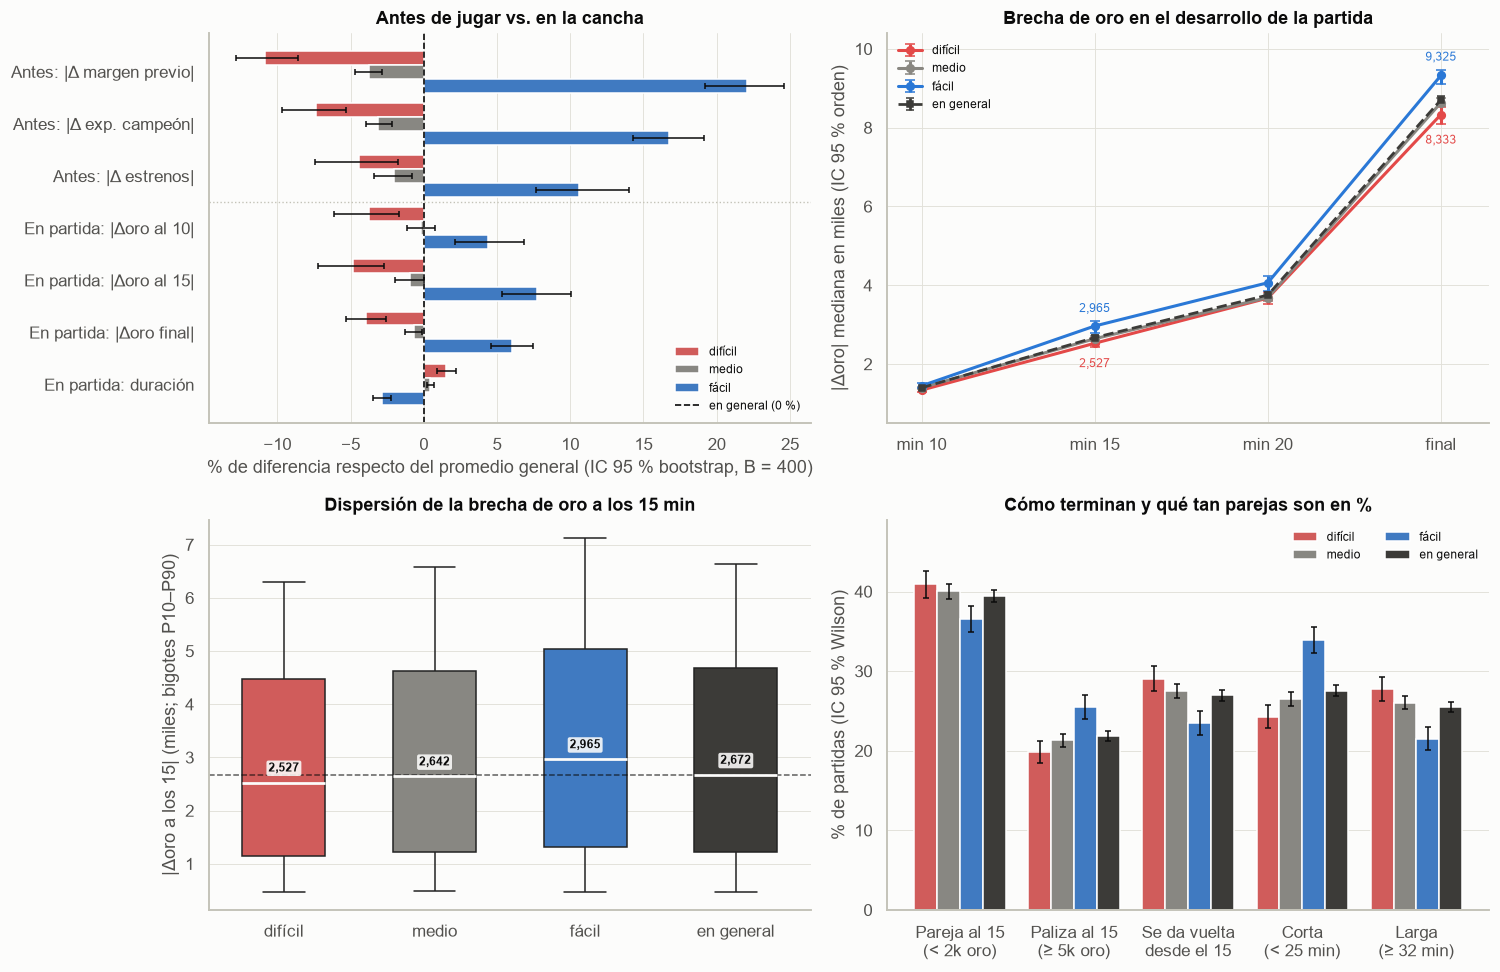

In [23]:
fig, ax = plt.subplots(2, 2, figsize=(13.8, 9.0))

# Panel A: % respecto de "en general" (medias) — Antes vs En partida (IC 95 % bootstrap pareado sobre partidas)
rel_cols = [
    ("Antes: |Δ margen previo|", np.abs(marg_eq[:, 0] - marg_eq[:, 1])),
    ("Antes: |Δ exp. campeón|", np.abs(exp_eq[:, 0] - exp_eq[:, 1])),
    ("Antes: |Δ estrenos|", np.abs(estr[:, 0] - estr[:, 1])),
    ("En partida: |Δoro al 10|", g10_abs),
    ("En partida: |Δoro al 15|", g15_abs),
    ("En partida: |Δoro final|", gfin_abs),
    ("En partida: duración", dur_v),
]
grp_arr = grupo.astype(str).to_numpy()
filas_a = []
for nom, arr in rel_cols:
    gen = np.nanmean(arr)
    arr_b = arr[BOOT]                                               # (B, n_V)
    gen_b = np.nanmean(arr_b, axis=1)
    grp_b = grp_arr[BOOT]
    for g in GR:
        m = grp_arr == g
        val_g = 100.0 * (np.nanmean(arr[m]) - gen) / gen
        mb = grp_b == g
        ok_b = mb & np.isfinite(arr_b)
        mean_b = np.where(ok_b, arr_b, 0.0).sum(axis=1) / np.maximum(ok_b.sum(axis=1), 1)
        dev_b = 100.0 * (mean_b - gen_b) / gen_b
        lo_a, hi_a = np.percentile(dev_b, [2.5, 97.5])
        filas_a.append({"indicador": nom, "grupo": g, "desvío (%)": val_g, "lo": lo_a, "hi": hi_a})
da = pd.DataFrame(filas_a)
ord_a = [x[0] for x in rel_cols]
sns.barplot(data=da, x="desvío (%)", y="indicador", hue="grupo", hue_order=GR, palette=col4,
            order=ord_a, ax=ax[0, 0])
for cont, g in zip(ax[0, 0].containers, GR):
    dg = da[da.grupo == g].set_index("indicador").loc[ord_a]
    ys_b = np.array([b.get_y() + b.get_height() / 2 for b in cont])
    ax[0, 0].errorbar(dg["desvío (%)"], ys_b,
                      xerr=[np.maximum(0.0, dg["desvío (%)"] - dg["lo"]),
                            np.maximum(0.0, dg["hi"] - dg["desvío (%)"])],
                      fmt="none", ecolor=INK, elinewidth=1.0, capsize=2.0, zorder=5)
ax[0, 0].axvline(0, color=INK, lw=1.1, ls="--", label="en general (0 %)")
ax[0, 0].axhline(2.5, color="#c3c2b7", lw=0.9, ls=":")
ax[0, 0].set_ylabel("")
ax[0, 0].set_xlabel(f"% de diferencia respecto del promedio general (IC 95 % bootstrap, B = {B})")
ax[0, 0].set_title("Antes de jugar vs. en la cancha")
ax[0, 0].legend(fontsize=8, loc="lower right", title="")

# Panel B: Evolución de |Δoro| mediana a lo largo de la partida (IC 95 % de la mediana por estadísticos de orden)
filas_b = []
moms_b = ["min 10", "min 15", "min 20", "final"]
for mom, arr in [("min 10", g10_abs), ("min 15", g15_abs), ("min 20", g20_abs), ("final", gfin_abs)]:
    med_, lo_, hi_ = median_ci(arr)
    filas_b.append({"momento": mom, "grupo": "en general", "oro_k": med_ / 1000, "lo": lo_ / 1000, "hi": hi_ / 1000})
    for g in GR:
        m = (grupo == g).to_numpy()
        med_, lo_, hi_ = median_ci(arr[m])
        filas_b.append({"momento": mom, "grupo": g, "oro_k": med_ / 1000, "lo": lo_ / 1000, "hi": hi_ / 1000})
db = pd.DataFrame(filas_b)
xb = np.arange(len(moms_b))
for g in GR:
    dg = db[db.grupo == g].set_index("momento").loc[moms_b]
    ax[0, 1].plot(xb, dg["oro_k"], marker="o", color=col4[g], lw=2, ms=5, label=g)
    ax[0, 1].fill_between(xb, dg["lo"], dg["hi"], color=col4[g], alpha=0.14, lw=0)
dg_all = db[db.grupo == "en general"].set_index("momento").loc[moms_b]
ax[0, 1].plot(xb, dg_all["oro_k"], marker="s", ls="--", color=col4["en general"], lw=1.8, ms=4.5, label="en general")
ax[0, 1].fill_between(xb, dg_all["lo"], dg_all["hi"], color=col4["en general"], alpha=0.12, lw=0)
for mom in ("min 15", "final"):
    im = moms_b.index(mom)
    rf = db[(db.momento == mom) & (db.grupo == "fácil")].iloc[0]
    rd = db[(db.momento == mom) & (db.grupo == "difícil")].iloc[0]
    ax[0, 1].annotate(f"{int(round(rf['oro_k'] * 1000)):,}", (im, rf["hi"]), xytext=(0, 6), textcoords="offset points",
                      ha="center", fontsize=8, color=col4["fácil"])
    ax[0, 1].annotate(f"{int(round(rd['oro_k'] * 1000)):,}", (im, rd["lo"]), xytext=(0, -13), textcoords="offset points",
                      ha="center", fontsize=8, color=col4["difícil"])
ax[0, 1].set_xticks(xb, moms_b)
ax[0, 1].set_xlim(-0.2, 3.28)
ax[0, 1].set_ylim(0.5, 10.4)
ax[0, 1].set_xlabel("")
ax[0, 1].set_ylabel("|Δoro| mediana en miles (IC 95 % orden)")
ax[0, 1].set_title("Brecha de oro en el desarrollo de la partida")
ax[0, 1].legend(fontsize=8, loc="upper left", title="")

# Panel C: Distribución de |Δoro a los 15| (boxplot P10-P90)
df_c = pd.concat([
    pd.DataFrame({"grupo": grupo[ok15].astype(str), "oro_k": g15_abs[ok15] / 1000}),
    pd.DataFrame({"grupo": "en general", "oro_k": g15_abs[ok15] / 1000}),
], ignore_index=True)
sns.boxplot(data=df_c, x="grupo", y="oro_k", hue="grupo", order=GR4, hue_order=GR4, palette=col4,
            whis=(10, 90), showfliers=False, width=0.55, dodge=False, legend=False,
            medianprops={"color": "#fcfcfb", "linewidth": 1.8}, ax=ax[1, 0])
ax[1, 0].axhline(np.median(g15_abs[ok15]) / 1000, color=INK, lw=1.0, ls="--", alpha=0.65)
for i, g in enumerate(GR4):
    med_g = df_c.loc[df_c.grupo == g, "oro_k"].median()
    ax[1, 0].text(i, med_g + 0.16, f"{int(round(med_g * 1000)):,}", ha="center", va="bottom",
                  fontsize=8, fontweight="bold", color=INK,
                  bbox=dict(boxstyle="round,pad=0.16", facecolor="#fcfcfb", edgecolor="none", alpha=0.88))
ax[1, 0].set_xlabel("")
ax[1, 0].set_ylabel("|Δoro a los 15| (miles; bigotes P10–P90)")
ax[1, 0].set_title("Dispersión de la brecha de oro a los 15 min")

# Panel D: Frecuencia de partidas parejas, palizas, remontadas y duración (IC 95 % Wilson)
ind_d = [
    ("Pareja al 15\n(< 2k oro)", np.where(ok15, (g15_abs < 2000).astype(float), np.nan)),
    ("Paliza al 15\n(≥ 5k oro)", np.where(ok15, (g15_abs >= 5000).astype(float), np.nan)),
    ("Se da vuelta\ndesde el 15", rem15_v),
    ("Corta\n(< 25 min)", (dur_v < 25).astype(float)),
    ("Larga\n(≥ 32 min)", (dur_v >= 32).astype(float)),
]
filas_d = []
ord_d = [x[0] for x in ind_d]
for nom, arr in ind_d:
    ok_a = np.isfinite(arr)
    p0 = float(arr[ok_a].mean())
    lo0, hi0 = wilson_ci(p0, int(ok_a.sum()))
    filas_d.append({"tipo": nom, "grupo": "en general", "pct": 100 * p0, "lo": 100 * float(lo0), "hi": 100 * float(hi0)})
    for g in GR:
        m = (grupo == g).to_numpy() & ok_a
        pg = float(arr[m].mean())
        log, hig = wilson_ci(pg, int(m.sum()))
        filas_d.append({"tipo": nom, "grupo": g, "pct": 100 * pg, "lo": 100 * float(log), "hi": 100 * float(hig)})
dd = pd.DataFrame(filas_d)
sns.barplot(data=dd, x="tipo", y="pct", hue="grupo", hue_order=GR4, palette=col4,
            order=ord_d, ax=ax[1, 1])
for cont, g in zip(ax[1, 1].containers, GR4):
    dg = dd[dd.grupo == g].set_index("tipo").loc[ord_d]
    xs_b = np.array([b.get_x() + b.get_width() / 2 for b in cont])
    ax[1, 1].errorbar(xs_b, dg["pct"],
                      yerr=[np.maximum(0.0, dg["pct"] - dg["lo"]), np.maximum(0.0, dg["hi"] - dg["pct"])],
                      fmt="none", ecolor=INK, elinewidth=1.0, capsize=2.0, zorder=5)
ax[1, 1].set_xlabel("")
ax[1, 1].set_ylabel("% de partidas (IC 95 % Wilson)")
ax[1, 1].set_ylim(0, 49)
ax[1, 1].set_title("Cómo terminan y qué tan parejas son en %")
ax[1, 1].legend(fontsize=8, loc="upper right", ncol=2, title="")

plt.tight_layout()
plt.show()

**Lectura.**

* **En la previa sí son más parejas, y en la cancha un poco.** Antes de jugar, las partidas
  *difíciles* tienen equipos más equilibrados en margen previo y experiencia con el campeón (−8 a
  −12 % frente al promedio general, contra +17 a +22 % en las *fáciles*); el tier no cambia porque el
  emparejamiento ya balancea el rango.
* **Difíciles vs. medias y en general:** una vez que arranca el partido, las difíciles se juegan
  apenas más parejas que las medias y el promedio general (mediana de |Δoro| al 15: 2.514 contra 2.642
  y 2.672, $p = 0{,}02$; al 20 ya no hay diferencia, 3.688 contra 3.690, $p = 0{,}21$; partidas con
  < 2.000 de oro al 15: 41,0 % contra 40,0 % y 39,5 %; palizas de ≥ 5.000: 19,8 % contra 21,3 % y 21,8 %).
* **Difíciles vs. fáciles:** frente a las fáciles la brecha es clara: las fáciles sacan ~18 % más de oro
  de mediana al 15 (2.964 contra 2.514) y ~10 % al 20 (4.060 contra 3.688), duran ~1,3 min menos (27,4
  contra 28,7 min), tienen más partidas cortas de < 25 min (33,9 % contra 24,3 %) y menos remontadas
  desde el 15 (23,5 % contra 29,0 %).
* **Lo que cambia no es si hay *snowball*, sino hacia qué lado cae.** Incluso en las partidas
  difíciles, 1 de cada 5 tiene ≥ 5.000 de oro de diferencia al minuto 15 y 1 de cada 4 dura menos
  de 25 minutos; y entre las fáciles, el 36,5 % igual llega a menos de 2.000 de oro al 15. Al
  revés, cuando una partida *termina* siendo pareja (≥ 32 min o < 2.000 al 15), el modelo sí pierde
  mucha señal (AUC 0,573 en ≥ 32 min contra 0,775 en < 25 min).

## 6.4 Las sorpresas: cuando la partida fácil sale al revés

En las partidas fáciles donde el modelo se equivoca, ¿la partida ya se veía torcida a los 10 y a
los 15 minutos, o el favorito iba adelante y la perdió después?

In [24]:
filas = []
for m in (10, 15, 20):
    g = D[f"d_gold_{m}"][val]
    ok = ~np.isnan(g)
    for nombre, sel in (("acertó", fac & acerto), ("falló", fac & ~acerto)):
        s = sel & ok
        adel = (np.sign(g[s]) == fav[s])
        filas.append({"minuto": m, "partida fácil": nombre, "partidas": int(s.sum()),
                      "el favorito va adelante": adel.mean(),
                      "Δoro del favorito (mediana)": np.median(g[s] * fav[s])})
t74 = pd.DataFrame(filas).pivot(index="minuto", columns="partida fácil")
display(t74.style.format("{:.1%}", subset=[c for c in t74.columns if c[0] == "el favorito va adelante"])
        .format("{:,.0f}", subset=[c for c in t74.columns if c[0] != "el favorito va adelante"])
        .set_caption("Partidas fáciles: dónde estaba el favorito durante la partida"))

## 6.5 Cuando el modelo duda: ¿apostar al rojo?

El lado rojo gana un poco más que el azul (51,9 % en el ajuste, 51,2 % en V). Propuesta: si el
modelo está menos seguro que un umbral $t$ ($\max(p, 1-p) < t$, con $t = 0{,}52$ como caso
pedido), en lugar de seguirlo, predecir **rojo** (el baseline del lado).

Para no elegir el umbral mirando V, se calcula también el logit **fuera de pliegue** en el
conjunto de ajuste (5 pliegues, mismo escalón 9). El umbral se decide ahí y se confirma en V.

In [25]:
from sklearn.model_selection import KFold

fi = fi_idx
logit_f = np.zeros(len(fi))
Cf_f = pd.DataFrame(0.0, index=range(len(fi)), columns=Cf.columns)
for a, b in KFold(5, shuffle=True, random_state=0).split(fi):
    m_ = LogisticRegression(C=0.05, max_iter=4000).fit(X_fit[a], y[fi[a]])
    Cf_f.iloc[b] = aportes(X_fit[b], m_.coef_[0]).to_numpy()
    logit_f[b] = m_.intercept_[0] + Cf_f.iloc[b].sum(1).to_numpy()
yf = y[fit]
p_f, p_v = 1 / (1 + np.exp(-logit_f)), 1 / (1 + np.exp(-logit_v))


filas = []
for t in (0.51, 0.52, 0.53, 0.55, 0.57, 0.60):
    fila = {"umbral t": t}
    for nom, p, yy in (("ajuste", p_f, yf), ("V", p_v, yv)):
        dud = np.abs(p - 0.5) < t - 0.5
        okm = (p > 0.5) == yy
        okr = np.where(dud, False, p > 0.5) == yy
        fila[f"{nom}: gana rojo en las dudosas"] = 1 - yy[dud].mean()
        fila[f"{nom}: Δ acierto total"] = okr.mean() - okm.mean()
    filas.append(fila)
t75 = pd.DataFrame(filas).set_index("umbral t")
display(t75.style.format_index("{:.2f}").format("{:.1%}", subset=[c for c in t75.columns if "dudosas" in c])
        .format("{:+.2%}", subset=[c for c in t75.columns if "Δ" in c])
        .set_caption("Regla «si duda, rojo»: cambio en el acierto total frente a seguir al modelo"))

,ajuste: gana rojo en las dudosas,ajuste: Δ acierto total,V: gana rojo en las dudosas,V: Δ acierto total
umbral t,,,,
0.51,51.1%,+0.07%,49.7%,-0.04%
0.52,51.0%,+0.01%,49.2%,-0.19%
0.53,51.0%,-0.04%,49.2%,-0.43%
0.55,50.6%,-0.34%,50.2%,-0.52%
0.57,50.6%,-0.83%,51.0%,-0.83%
0.60,50.6%,-1.72%,50.5%,-1.66%


**Lectura.** La regla no sirve, y la razón es que el modelo **ya la tiene adentro**: su
intercepto es la ventaja del rojo. Una partida en la que el modelo da ~50 % es una en la que los
jugadores favorecen al azul lo justo para compensar esa ventaja. En esas partidas el rojo gana la
mitad de las veces, no el 51-52 %, así que forzar "rojo" cambia moneda por moneda. Con $t = 0{,}52$
el acierto total casi no se mueve, y con umbrales más altos baja, porque ahí el modelo ya sabe
algo.

En las difíciles, lo honesto es **no predecir** (abstenerse) en lugar de inventar un lado. Para
la demo o el informe conviene reportar el acierto según la cobertura (gráfico «Acierto según la
confianza», al principio de la sección 6), no forzar una
predicción en cada partida.

**Lectura de la sección 6.**

* **Una partida difícil no es una partida sin información: es una partida donde la información se
  contradice.** En las difíciles, las familias se cancelan casi por completo (conflicto 0,95) y el
  acierto es el de una moneda (52 %). En las fáciles, 13 de las 21 familias empujan hacia el mismo
  equipo y el acierto sube a 76 %.
* **Pesan las mismas cosas en los dos extremos.** Champion Mastery y margen acumulado son ~40 % del
  empuje a favor del favorito en los tres grupos (algo más en las difíciles); les siguen el modelo por
  línea (10-13 %) y el margen jugador-campeón (5-10 %). Lo que cambia es el tamaño y el acuerdo, no qué
  familia manda.
* **El draft opina igual en todas las partidas, pero se cancela.** Las familias de campeones (draft,
  Champion Stats, Champion Style, contracruces y duelo esperado) se mueven lo mismo en los tres grupos
  (panel derecho), y su empuje neto hacia el favorito es chico en todos: los dos equipos suelen tener
  drafts parecidos en fuerza. Lo que crece de las difíciles a las fáciles es el historial de los
  jugadores.
* **Pool, WR de sesión y Rol Mastery empujan en contra del favorito**: dado el margen, funcionan como
  corrección (un winrate alto con el mismo margen anticipa una vuelta a la media; un pool muy
  concentrado, que el margen sobrestima al especialista). Por eso sacar el pool cuesta AUC (sección 4)
  aunque solo no prediga nada.
* **Lo que hace fácil un lobby es la asimetría entre los equipos**, no el tipo de lobby. Las
  partidas fáciles tienen bastante más diferencia de margen (×1,4) y de estrenos (×1,2) entre equipos,
  pero el mismo tier, el mismo historial y casi la misma cantidad total de estrenos.
* **Difícil de predecir no es lo mismo que pareja en la cancha (6.3):** en los datos previos, las
  difíciles llegan más equilibradas (−8 a −12 % frente al promedio general en margen y experiencia,
  contra +17 a +22 % en las fáciles). Durante la partida son apenas más parejas que las medias al 15
  (mediana 2.514 contra 2.642, $p = 0{,}02$) e iguales al 20; las fáciles abren ~18 % más de ventaja
  en oro al 15, terminan antes y tienen más rendiciones tempranas, y en ellas el favorito va adelante
  a los 15 el 69 % de las veces (en las difíciles, el 51 %: otra moneda).
* **Las sorpresas se deciden temprano.** Cuando una partida fácil sale al revés, el favorito ya iba
  atrás en oro a los 10 minutos en 3 de cada 5 casos, y a los 15 en casi 2 de cada 3. No son partidas
  tiradas al final: el favorito pierde la fase de líneas.
* **Qué hacer con cada grupo.** En las difíciles, apostar al rojo no suma nada, porque el modelo
  ya descuenta la ventaja del lado; lo que corresponde es abstenerse. En las fáciles, no hay nada
  que exprimir antes de la partida más allá de ordenar por la probabilidad; sí sirve confirmar al
  minuto 10.

# 7. ¿Se podría armar una partida más pareja?

Si el modelo previo sabe qué equipo llega favorito, la pregunta inversa es natural: **con los mismos
10 jugadores, ¿se podría haber armado una partida más pareja?** Por ejemplo, pasando a los dos tops al
otro equipo, o intercambiando de posición a dos jugadores que juegan bastante mid y top, siempre que
los roles no se vean muy afectados.

El estudio tiene tres piezas (§9.S.67):

1. **Compuerta.** Antes de usar la probabilidad del modelo como medida de "qué tan pareja" es una
   partida, hay que verificar que esté **calibrada**: que cuando dice 60 %, ese equipo gane el 60 %.
2. **Desvío de rol.** Para cada jugador, cuánto se aleja la posición que le toca de la que más juega.
   Con la distribución de roles de **sus partidas anteriores**, suavizada hacia la global $q$ para los
   que tienen poco historial, $\pi_i(r) = (n_{i,r} + 5\, q_r)/(n_i + 5)$ y
   $d_i(r) = \max_s \pi_i(s) - \pi_i(r) \in [0, 1]$: vale 0 en su rol principal y es bajo en
   cualquier línea para quien juega de todo. El costo de rol de una partida es $D = \sum_i d_i$.
3. **Reacomodos.** Se prueban todas las formas válidas de reacomodar a los 10 jugadores y se mide cuánto
   se acerca la probabilidad a 50-50 y cuánto cambia el desvío de rol.

**Con qué modelo se puntúa.** El emparejamiento ocurre **antes del draft**: si un jugador pasa de mid a
top, no puede llevarse su campeón de mid. Por eso los reacomodos se puntúan con el escalón 9 **sin el
draft ni las variables que dependen del campeón elegido** (320 columnas de jugador y de jugador × línea).
Pierde 0,037 de AUC, pero es la única versión en la que "el mismo jugador en otra línea" está definido.

Todo es V Master+. Los números salen de `data/analysis/matchmaking/`, que escriben:

    python scripts/analysis/matchmaking_calibracion.py   # compuerta (~100 s)
    python scripts/analysis/matchmaking_perfil_roles.py  # perfil de roles (~45 s)
    python -u scripts/analysis/matchmaking_swaps.py      # reacomodos (~150 s)

In [27]:
MM = ROOT / "data" / "analysis" / "matchmaking"
_falta = [f for f in ("calib_v_escalon9.parquet", "calib_v_sin_draft.parquet", "swaps_resultados.parquet",
                      "swaps_jugadores.parquet") if not (MM / f).exists()]
if _falta:
    raise FileNotFoundError(f"Faltan {_falta}: correr los tres scripts matchmaking_*.py de arriba")
mm_cal = {"Escalón 9 (con draft)": pd.read_parquet(MM / "calib_v_escalon9.parquet"),
          "Sin draft (para reacomodar)": pd.read_parquet(MM / "calib_v_sin_draft.parquet")}
mm_r = pd.read_parquet(MM / "swaps_resultados.parquet")
mm_j = pd.read_parquet(MM / "swaps_jugadores.parquet")
desb = lambda p: 100 * np.abs(np.asarray(p) - 0.5)                      # desbalance en puntos de probabilidad
pareja = lambda p: ((np.asarray(p) >= 0.45) & (np.asarray(p) <= 0.55)).mean()
print(f"V Master+: {len(mm_r):,} partidas, {len(mm_j) // mm_j['escenario'].nunique():,} jugador-partida.")

V Master+: 16,428 partidas, 164,280 jugador-partida.


## 7.1 Antes: ¿las probabilidades del modelo son confiables?

Diagrama de confiabilidad por deciles de la probabilidad, con los dos modelos en el mismo gráfico y el
IC 95 % bootstrap de lo que efectivamente ganó el azul como banda. Además, la recta de calibración $\operatorname{logit} P(\text{gana azul}) = a + b \cdot
\operatorname{logit}(p)$: $b = 1$ es calibrado, $b < 1$ sobreconfiado (exagera) y $b > 1$ subconfiado.

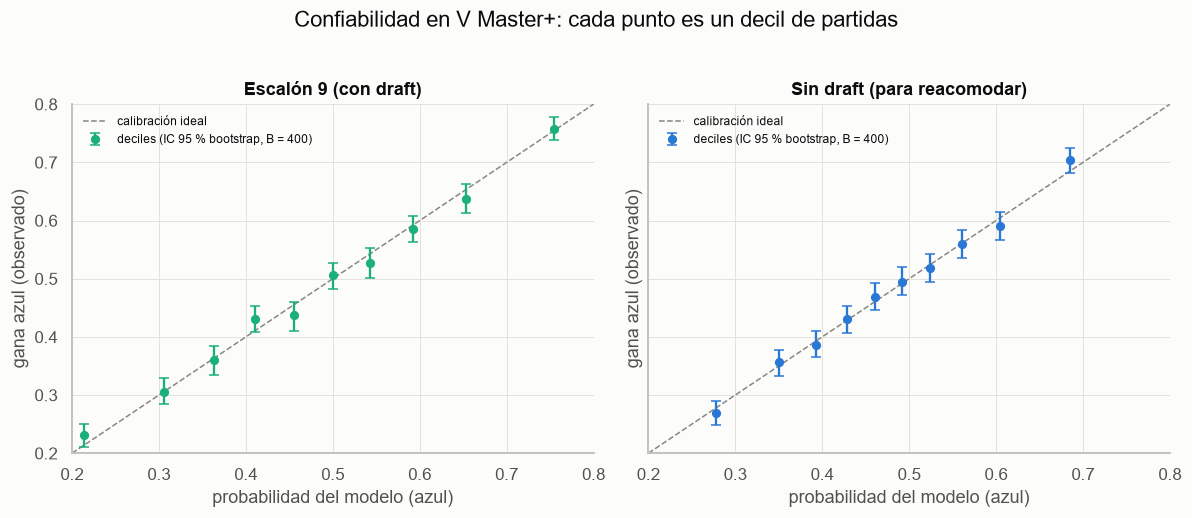

modelo,AUC,Accuracy,ECE (deciles),intercepto a,pendiente b,favorito al ~60 %: partidas,favorito al ~60 %: gana
Escalón 9 (con draft),0.6740,62.6%,1.04%,-0.011,0.952,"3,269",59.4%
Sin draft (para reacomodar),0.6369,59.6%,0.75%,+0.004,1.028,"3,918",60.0%


In [28]:
rng_mm = np.random.default_rng(0)
fig, ax = plt.subplots(figsize=(7.2, 5.6))
ax.plot([0.2, 0.8], [0.2, 0.8], ls="--", color=MUTED, lw=1, label="calibración ideal")
filas = []
for (nom, df), col, mk in zip(mm_cal.items(), (CATEGORICAL[2], CATEGORICAL[0]), ("o", "s")):
    p, yy = df["p_azul"].to_numpy(), df["y"].to_numpy().astype(int)
    dec = pd.qcut(p, 10, labels=False)
    g = pd.DataFrame({"p": p, "y": yy, "d": dec}).groupby("d").agg(p=("p", "mean"), r=("y", "mean"), n=("y", "size"))
    ic = np.array([[rng_mm.choice(yy[dec == k], (dec == k).sum()).mean() for _ in range(400)] for k in g.index])
    lo, hi = np.percentile(ic, 2.5, axis=1), np.percentile(ic, 97.5, axis=1)
    ax.plot(g.p, g.r, marker=mk, color=col, lw=1.8, ms=5, label=nom)
    ax.fill_between(g.p, lo, hi, color=col, alpha=0.15, lw=0)
    lg = np.log(p / (1 - p))
    rc = LogisticRegression(C=1e9, max_iter=1000).fit(lg[:, None], yy)
    fav, gana_fav = np.maximum(p, 1 - p), np.where(p >= 0.5, yy, 1 - yy)
    s60 = (fav >= 0.575) & (fav < 0.625)
    filas.append({"modelo": nom, "AUC": roc_auc_score(yy, p), "Accuracy": ((p > 0.5) == yy).mean(),
                  "ECE (deciles)": (np.abs(g.p - g.r) * g.n).sum() / g.n.sum(),
                  "intercepto a": rc.intercept_[0], "pendiente b": rc.coef_[0, 0],
                  "favorito al ~60 %: partidas": s60.sum(), "favorito al ~60 %: gana": gana_fav[s60].mean()})
ax.set(xlabel="probabilidad del modelo (azul)", ylabel="gana azul (observado)", xlim=(0.2, 0.8), ylim=(0.2, 0.8),
       title="Confiabilidad en V Master+: cada punto es un decil de partidas")
ax.set_xlabel("probabilidad del modelo (azul) · banda: IC 95 % bootstrap por decil, B = 400")
ax.legend(fontsize=8.5, loc="upper left")
plt.tight_layout(); plt.show()
display(pd.DataFrame(filas).style.hide(axis="index")
        .format({"AUC": "{:.4f}", "Accuracy": "{:.1%}", "ECE (deciles)": "{:.2%}", "intercepto a": "{:+.3f}",
                 "pendiente b": "{:.3f}", "favorito al ~60 %: partidas": "{:,}", "favorito al ~60 %: gana": "{:.1%}"})
        .set_caption("Calibración del modelo previo (favorito al ~60 % = probabilidad del favorito entre 57,5 y 62,5 %)"))

**Lectura.** Los puntos caen sobre la diagonal en los dos modelos: **cuando el modelo le da ~60 % a un
equipo, ese equipo gana el ~60 %**, y lo mismo en los extremos (los lobbies que ve muy desparejos
realmente lo son). La pendiente queda en 0,95 con draft y 1,03 sin draft, con IC que incluye 1, y
se sostiene en los tres tramos de fecha de V (`REPORTE_calibracion.md`). Recalibrar (Platt, ajustado
antes de V) no mejora, así que se usa la probabilidad tal cual. **La compuerta se pasa:**
$|p - 0{,}5|$ es una medida válida de qué tan despareja llega una partida. (En Diamond los dos modelos
sí exageran, $b \approx 0{,}83$; el estudio es solo Master+.)

## 7.2 Los reacomodos posibles

Para cada partida se enumeran **todas** las configuraciones válidas (en promedio 126 por partida):

* **(a) Misma línea, otro equipo.** Los dos jugadores de una línea cambian de equipo (los dos tops,
  por ejemplo). $2^5 = 32$ combinaciones, y **ningún jugador cambia de rol**.
* **(b) Cambio de rol.** Dos jugadores intercambian posición (del mismo equipo o de equipos distintos)
  solo si los dos juegan bastante el rol del otro: $\pi_i(\text{rol nuevo}) \ge \tau$, con $\tau = 0{,}20$ o
  $0{,}35$.
* **(a+b)** Todas las combinaciones de las dos.

De cada partida se queda la configuración con la probabilidad más cerca de 0,5. Con "$D \le D_{\text{real}}$"
solo se admiten las que no empeoran el desvío total de rol respecto de lo que armó Riot.

La probabilidad de cada configuración se recalcula **exacta**: las variables del jugador se mueven con
él, las de jugador × línea (cuánto juega esa línea, su margen y winrate en ella) se recalculan para la
línea nueva con su historial previo, y los agregados por equipo (mínimos, máximos) se rehacen. Con la
asignación real reproduce la probabilidad del modelo (diferencia máxima $3 \cdot 10^{-7}$).

In [30]:
ESC = {"real": "Riot (real)", "a_misma_linea": "(a) misma línea",
       "b_rol_t20_d_le": "(b) un cambio de rol, τ 0,20, D ≤ D real",
       "ab_exh_t35_d_le": "(a+b) τ 0,35, D ≤ D real", "ab_exh_t20_d_le": "(a+b) τ 0,20, D ≤ D real",
       "ab_exh_t20_sin_tope": "(a+b) τ 0,20, sin tope de D", "ab_minD_t20": "(a+b) τ 0,20, primero el menor D"}
filas = []
for k, nom in ESC.items():
    p = mm_r[f"p_{k}"]
    filas.append({"escenario": nom, "|p − 0,5| medio (pp)": desb(p).mean(), "|p − 0,5| mediana (pp)": np.median(desb(p)),
                  "partidas entre 45 y 55 %": pareja(p), "partidas entre 48 y 52 %": (desb(p) <= 2).mean(),
                  "D medio": mm_r[f"D_{k}"].mean(), "fuera de su rol principal": mm_r[f"n_fuera_{k}"].mean() / 10})
t73 = pd.DataFrame(filas).set_index("escenario")
display(t73.style.format({"|p − 0,5| medio (pp)": "{:.2f}", "|p − 0,5| mediana (pp)": "{:.2f}", "partidas entre 45 y 55 %": "{:.1%}",
                          "partidas entre 48 y 52 %": "{:.1%}", "D medio": "{:.3f}", "fuera de su rol principal": "{:.1%}"})
        .set_caption("Mejor reacomodo por partida, medido con el mismo modelo que lo elige (V Master+)"))

,"|p − 0,5| medio (pp)","|p − 0,5| mediana (pp)",partidas entre 45 y 55 %,partidas entre 48 y 52 %,D medio,fuera de su rol principal
escenario,,,,,,
Riot (real),9.74,8.50,30.6%,12.4%,1.252,31.8%
(a) misma línea,1.17,0.54,95.8%,82.9%,1.252,31.8%
"(b) un cambio de rol, τ 0,20, D ≤ D real",8.24,6.66,40.4%,18.4%,1.136,29.8%
"(a+b) τ 0,35, D ≤ D real",0.99,0.40,96.7%,86.3%,1.149,29.5%
"(a+b) τ 0,20, D ≤ D real",0.73,0.21,97.7%,90.5%,1.073,29.0%
"(a+b) τ 0,20, sin tope de D",0.59,0.15,98.3%,92.9%,1.151,31.4%
"(a+b) τ 0,20, primero el menor D",1.14,0.53,96.0%,83.6%,0.900,25.7%


**Lectura.** Medido con el mismo modelo que elige, casi cualquier partida se puede llevar a 50-50, y casi
todo el equilibrio sale de **(a)**, que no saca a nadie de su rol. Los cambios de rol solos (b) aportan
poco equilibrio, pero combinados permiten algo más interesante: **bajar el desvío de rol por debajo del
de Riot** (D de 1,25 a 1,07, o a 0,90 si se prioriza el rol). Son los casos de dos jugadores en autofill
que juegan cada uno el rol del otro.

Pero esta tabla es **optimista a propósito**: elegir el mínimo entre ~126 configuraciones con un modelo
estimado encuentra configuraciones que *parecen* parejas por el ruido del modelo. La sección siguiente lo
descuenta.

## 7.3 Descontar el sesgo de optimización

Se ajustan **dos modelos con mitades disjuntas** del entrenamiento (partidas intercaladas por fecha). El
modelo A elige el reacomodo y el B lo evalúa, y al revés. Si la mejora fuera solo ruido de A, B no la
vería. Para que la comparación sea justa, la asignación de Riot también se mide con los modelos de
mitad.

,"Riot: |p − 0,5|","elegido: |p − 0,5|","independiente: |p − 0,5|",mejora que sobrevive,Riot: parejas,independiente: parejas
escenario,,,,,,
(a) misma línea,10.025956,1.061360,5.064365,55%,29.7%,56.8%
"(a+b) τ 0,20, D ≤ D real",10.025956,0.657846,4.870527,55%,29.7%,58.6%
"(a+b) τ 0,20, primero el menor D",10.025956,1.032035,4.947693,56%,29.7%,57.9%


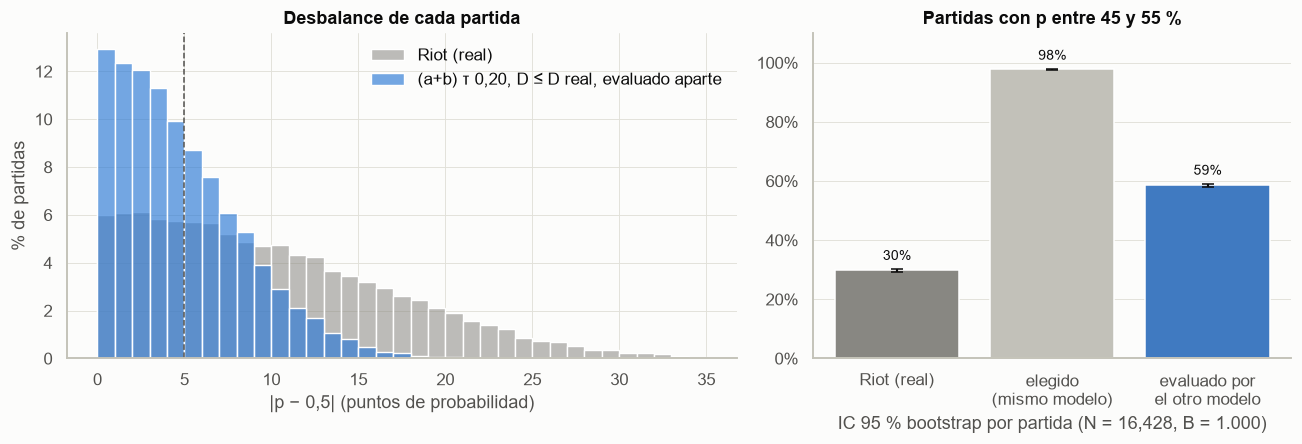

In [31]:
filas, dist = [], {}
real_ab = np.r_[mm_r["p_a_real"], mm_r["p_b_real"]]
for k in ("a_misma_linea", "ab_exh_t20_d_le", "ab_minD_t20"):
    eleg = np.r_[mm_r[f"p_a_eleg_{k}"], mm_r[f"p_b_eleg_{k}"]]
    indep = np.r_[mm_r[f"p_b_indep_{k}"], mm_r[f"p_a_indep_{k}"]]
    filas.append({"escenario": ESC[k], "Riot: |p − 0,5|": desb(real_ab).mean(), "elegido: |p − 0,5|": desb(eleg).mean(),
                  "independiente: |p − 0,5|": desb(indep).mean(),
                  "mejora que sobrevive": (desb(real_ab).mean() - desb(indep).mean()) / (desb(real_ab).mean() - desb(eleg).mean()),
                  "Riot: parejas": pareja(real_ab), "independiente: parejas": pareja(indep)})
    dist[ESC[k]] = indep
t74 = pd.DataFrame(filas).set_index("escenario")
display(t74.style.format({c: "{:.2f}" for c in t74.columns if "|p" in c})
        .format({"mejora que sobrevive": "{:.0%}", "Riot: parejas": "{:.1%}", "independiente: parejas": "{:.1%}"})
        .set_caption("Desbalance medio (pp) y partidas parejas (p entre 45 y 55 %), elegido contra evaluado por el otro modelo"))

k = "(a+b) τ 0,20, D ≤ D real"
fig, axes = plt.subplots(1, 2, figsize=(12, 4.2), gridspec_kw={"width_ratios": [1.4, 1]})
bins = np.linspace(0, 35, 36)
sns.histplot(desb(real_ab), bins=bins, stat="percent", color=MUTED, alpha=0.55, label="Riot (real)", ax=axes[0])
sns.histplot(desb(dist[k]), bins=bins, stat="percent", color=CATEGORICAL[0], alpha=0.65, label=f"{k}, evaluado aparte", ax=axes[0])
axes[0].axvline(5, ls="--", color=INK_2, lw=1)
axes[0].set(title="Desbalance de cada partida", xlabel="|p − 0,5| (puntos de probabilidad)", ylabel="% de partidas")
axes[0].legend()
# IC 95 % por partida (bootstrap B=1.000 sobre las N partidas; no duplica N al combinar mitades A y B)
_es_par = lambda p: ((np.asarray(p) >= 0.45) & (np.asarray(p) <= 0.55)).astype(float)
_z_par = [
    0.5 * (_es_par(mm_r["p_a_real"]) + _es_par(mm_r["p_b_real"])),
    0.5 * (_es_par(mm_r["p_a_eleg_ab_exh_t20_d_le"]) + _es_par(mm_r["p_b_eleg_ab_exh_t20_d_le"])),
    0.5 * (_es_par(mm_r["p_b_indep_ab_exh_t20_d_le"]) + _es_par(mm_r["p_a_indep_ab_exh_t20_d_le"])),
]
_rng_p = np.random.default_rng(74)
_b_idx = _rng_p.integers(0, len(mm_r), size=(1000, len(mm_r)))
_par_ic = [np.percentile(z[_b_idx].mean(axis=1), [2.5, 97.5]) for z in _z_par]
barras = pd.DataFrame({
    "versión": ["Riot (real)", "elegido\n(mismo modelo)", "evaluado por\nel otro modelo"],
    "partidas parejas": [float(z.mean()) for z in _z_par],
    "lo": [float(c[0]) for c in _par_ic],
    "hi": [float(c[1]) for c in _par_ic],
})
sns.barplot(barras, x="versión", y="partidas parejas", hue="versión", palette=[MUTED, "#c3c2b7", CATEGORICAL[0]], legend=False, ax=axes[1])
axes[1].errorbar(np.arange(len(barras)), barras["partidas parejas"],
                 yerr=[np.maximum(0.0, barras["partidas parejas"] - barras["lo"]),
                       np.maximum(0.0, barras["hi"] - barras["partidas parejas"])],
                 fmt="none", ecolor=INK, elinewidth=1.4, capsize=4, zorder=5)
for i_b, r_b in barras.iterrows():
    axes[1].text(i_b, r_b["hi"] + 0.02, f"{r_b['partidas parejas']:.0%}", ha="center", va="bottom", fontsize=9, color=INK)
axes[1].set(title="Partidas con p entre 45 y 55 %", xlabel=f"IC 95 % bootstrap por partida (N = {len(mm_r):,}, B = 1.000)",
            ylabel="", ylim=(0, 1.10))
axes[1].yaxis.set_major_formatter(plt.matplotlib.ticker.PercentFormatter(1))
plt.tight_layout(); plt.show()

**Lectura.** Cuando el reacomodo lo evalúa un modelo que no lo eligió, **sobrevive un poco más de la
mitad de la mejora**: el desbalance medio baja de ~10 a ~5 puntos y **las partidas parejas pasan de ~30 % a
~59 %, casi el doble**, sin empeorar el rol de nadie en total. El 98 % de la tabla anterior era en buena
parte el modelo encontrando su propio ruido.

Aun así es una **cota optimista**: los dos modelos comparten las variables (que miden con error la
habilidad de cada jugador), así que solo se descuenta el ruido de los coeficientes. Y los reacomodos
nunca se jugaron: la mejora no se puede verificar con resultados reales. A favor de que la señal sea real
está la sección 7.1: los desbalances grandes que el modelo ve en las partidas reales se confirman en los
resultados.

## 7.4 El costo de rol, jugador por jugador

¿Cuánto se desvía cada jugador de su rol principal en la partida reacomodada, comparado con la posición
que le dio Riot?

,d medio,d p90,"d > 0,3",fuera de su rol principal,mejora su d,empeora su d,cambia de rol,cambia de equipo
escenario,,,,,,,,
Riot (real),0.125,0.517,0.195422,0.318359,0.000000,0.000000,0.000000,0.000000
(a) misma línea,0.125,0.517,0.195422,0.318359,0.000000,0.000000,0.000000,0.492452
"(a+b) τ 0,20, D ≤ D real",0.107,0.463,0.163952,0.289914,0.069875,0.032505,0.102411,0.495617
"(a+b) τ 0,20, sin tope de D",0.115,0.472,0.177404,0.313623,0.073850,0.058924,0.132798,0.496311
"(a+b) τ 0,20, primero el menor D",0.090,0.400,0.134417,0.257475,0.112917,0.040833,0.153780,0.494327


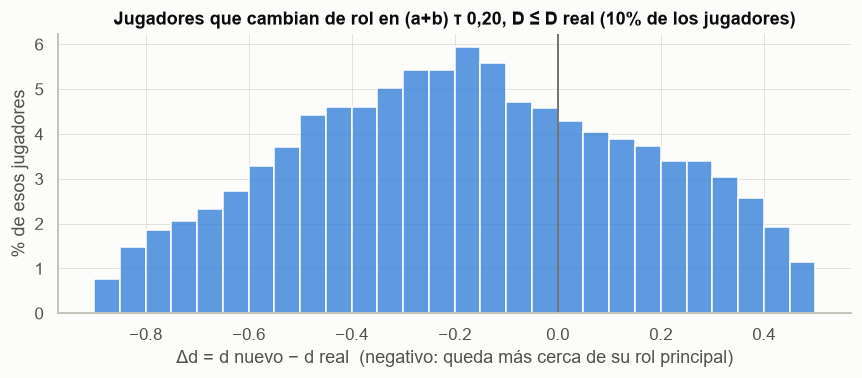

In [32]:
filas = []
for k in ("a_misma_linea", "ab_exh_t20_d_le", "ab_exh_t20_sin_tope", "ab_minD_t20"):
    s = mm_j[mm_j["escenario"] == k]
    if k == "a_misma_linea":
        filas.append({"escenario": "Riot (real)", "d medio": s["d_real"].mean(), "d p90": s["d_real"].quantile(0.9),
                      "d > 0,3": (s["d_real"] > 0.3).mean(), "fuera de su rol principal": (s["linea_real"] != s["rol_principal"]).mean(),
                      "mejora su d": 0.0, "empeora su d": 0.0, "cambia de rol": 0.0, "cambia de equipo": 0.0})
    filas.append({"escenario": ESC[k], "d medio": s["d_nuevo"].mean(), "d p90": s["d_nuevo"].quantile(0.9),
                  "d > 0,3": (s["d_nuevo"] > 0.3).mean(), "fuera de su rol principal": (s["linea_nueva"] != s["rol_principal"]).mean(),
                  "mejora su d": (s["delta_d"] < -1e-6).mean(), "empeora su d": (s["delta_d"] > 1e-6).mean(),
                  "cambia de rol": s["cambio_rol"].mean(), "cambia de equipo": s["cambio_equipo"].mean()})
t75 = pd.DataFrame(filas).set_index("escenario")
display(t75.style.format("{:.1%}").format({"d medio": "{:.3f}", "d p90": "{:.3f}"})
        .set_caption("Desvío de cada jugador respecto de su rol principal (V Master+, 164.280 jugador-partida)"))

s = mm_j[mm_j["escenario"] == "ab_exh_t20_d_le"]
mov = s[s["cambio_rol"]]
fig, ax = plt.subplots(figsize=(8, 3.6))
sns.histplot(mov["delta_d"], bins=np.linspace(-0.9, 0.5, 29), stat="percent", color=CATEGORICAL[0], ax=ax)
ax.axvline(0, color=INK_2, lw=1)
ax.set(title=f"Jugadores que cambian de rol en (a+b) τ 0,20, D ≤ D real ({len(mov) / len(s):.0%} de los jugadores)",
       xlabel="Δd = d nuevo − d real  (negativo: queda más cerca de su rol principal)", ylabel="% de esos jugadores")
plt.tight_layout(); plt.show()

**Lectura.** Con la restricción de no empeorar el total, **9 de cada 10 jugadores quedan en la misma
línea** (la mitad cambia de equipo, que no afecta su rol). De los que cambian de rol, la mayoría queda
**más cerca** de su rol principal: el reacomodo devuelve a su línea a jugadores que Riot había mandado
a otra. Por eso baja tanto la cola de los muy desviados ($d > 0{,}3$) como el porcentaje fuera de su rol
principal. Si se prioriza el rol (primero el menor $D$), el % fuera de rol principal cae de 32 % a 26 %
casi sin perder equilibrio.

## 7.5 El autofill desparejo explica parte del favorito

Si un equipo tiene más jugadores fuera de rol que el otro, ¿llega como no favorito? Y, sobre todo, ¿pierde
de verdad más seguido? Esto se puede comprobar con resultados reales.

,partidas,probabilidad del modelo,gana azul (real)
tramo,,,
≤ −1,574,57.8%,63.4%
"−1 a −0,5","2,150",53.5%,54.7%
"−0,5 a −0,2","2,742",50.6%,51.0%
"parejo (±0,2)","5,371",47.8%,47.5%
"0,2 a 0,5","2,807",44.9%,44.4%
"0,5 a 1","2,200",42.2%,41.6%
≥ 1,584,37.2%,34.4%


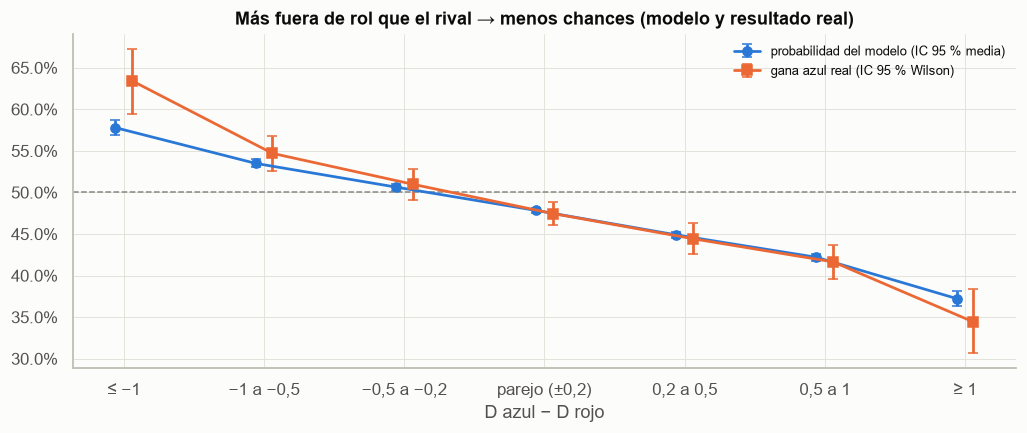

corr(p azul − 0,5 ; D azul − D rojo) = -0.38


In [33]:
asim = mm_r["D_azul_real"] - mm_r["D_rojo_real"]
tramos = pd.cut(asim, [-5, -1, -0.5, -0.2, 0.2, 0.5, 1, 5],
                labels=["≤ −1", "−1 a −0,5", "−0,5 a −0,2", "parejo (±0,2)", "0,2 a 0,5", "0,5 a 1", "≥ 1"])
g76 = pd.DataFrame({"tramo": tramos, "p": mm_r["p_real"], "y": mm_r["y"]}).groupby("tramo", observed=True).agg(
    partidas=("y", "size"), **{"probabilidad del modelo": ("p", "mean"), "gana azul (real)": ("y", "mean")})
display(g76.style.format({"partidas": "{:,}", "probabilidad del modelo": "{:.1%}", "gana azul (real)": "{:.1%}"})
        .set_caption("Según la diferencia de desvío de rol D azul − D rojo (positivo: el azul está más fuera de rol)"))
g76_full = pd.DataFrame({"tramo": tramos, "p": mm_r["p_real"], "y": mm_r["y"]}).groupby("tramo", observed=True).agg(
    partidas=("y", "size"), p_mean=("p", "mean"), p_se=("p", "sem"), y_mean=("y", "mean"))
lo_y76, hi_y76 = wilson_ci(g76_full["y_mean"].to_numpy(), g76_full["partidas"].to_numpy())
xs76 = np.arange(len(g76_full))
fig, ax = plt.subplots(figsize=(9.5, 4.1))
ax.plot(xs76, g76_full["p_mean"], marker="o", color=CATEGORICAL[0], lw=1.8, ms=6,
        label="probabilidad del modelo (IC 95 % media)")
ax.fill_between(xs76, g76_full["p_mean"] - Z95 * g76_full["p_se"], g76_full["p_mean"] + Z95 * g76_full["p_se"],
                color=CATEGORICAL[0], alpha=0.15, lw=0)
ax.plot(xs76, g76_full["y_mean"], marker="s", color=CATEGORICAL[1], lw=1.8, ms=6, label="gana azul real (IC 95 % Wilson)")
ax.fill_between(xs76, lo_y76, hi_y76, color=CATEGORICAL[1], alpha=0.15, lw=0)
ax.axhline(0.5, ls="--", color=MUTED, lw=1)
ax.set_xticks(xs76, list(g76_full.index))
ax.yaxis.set_major_formatter(plt.matplotlib.ticker.PercentFormatter(1))
ax.set(title="Más fuera de rol que el rival → menos chances (modelo y resultado real)", xlabel="D azul − D rojo", ylabel="")
ax.legend(fontsize=8.5, loc="upper right")
plt.tight_layout(); plt.show()
print(f"corr(p azul − 0,5 ; D azul − D rojo) = {np.corrcoef(mm_r['p_real'] - 0.5, asim)[0, 1]:+.2f}")

**Lectura.** El equipo con más desvío de rol llega como no favorito, y **los resultados reales lo
confirman**: el win rate observado acompaña a la probabilidad en todos los tramos, y en los extremos el
modelo incluso se queda corto (con el azul mucho menos fuera de rol que el rival, $D$ azul − $D$ rojo ≤ −1, el
modelo le da ~58 % y gana el ~63 %). Es la parte del
desbalance que se puede corregir sin tocar la habilidad de nadie, devolviendo jugadores a su rol. En cambio,
el desvío *total* de la partida casi no se relaciona con qué tan despareja llega ($r = 0{,}06$): si los dos
equipos tienen autofill, se compensa.

## 7.6 Un ejemplo

Una partida real de V Master+ (jugadores anonimizados) y el reacomodo elegido con (a+b), $\tau = 0{,}20$,
$D \le D_{\text{real}}$.

In [34]:
import hashlib
mid = next(m for m in mm_r["match_id"]  # partida de ejemplo, elegida por hash para no publicar su ID
           if hashlib.sha256(m.encode()).hexdigest()[:16] == "731539900fe699cd")
ej = mm_j[(mm_j["escenario"] == "ab_exh_t20_d_le") & (mm_j["match_id"] == mid)].copy()
ej["jugador"] = [f"Jugador {i}" for i in range(1, 11)]
fila = mm_r.set_index("match_id").loc[mid]
print(f"Probabilidad del azul: Riot {fila['p_real']:.1%} → reacomodo {fila['p_ab_exh_t20_d_le']:.1%}   |   "
      f"D: {fila['D_real']:.2f} → {fila['D_ab_exh_t20_d_le']:.2f}   |   ganó {'azul' if fila['y'] == 1 else 'rojo'}")
display(ej[["jugador", "rol_principal", "equipo_real", "linea_real", "d_real", "equipo_nuevo", "linea_nueva", "d_nuevo"]]
        .rename(columns={"rol_principal": "rol principal", "equipo_real": "equipo (Riot)", "linea_real": "línea (Riot)",
                         "d_real": "d (Riot)", "equipo_nuevo": "equipo (nuevo)", "linea_nueva": "línea (nueva)", "d_nuevo": "d (nuevo)"})
        .style.hide(axis="index").format({"d (Riot)": "{:.2f}", "d (nuevo)": "{:.2f}"})
        .apply(lambda r: [RESALTE if r["línea (Riot)"] != r["línea (nueva)"] else "" for _ in r], axis=1)
        .set_caption("Resaltados: los jugadores que cambian de línea"))

Probabilidad del azul: Riot 77.2% → reacomodo 50.0%   |   D: 3.41 → 0.57   |   ganó azul


jugador,rol principal,equipo (Riot),línea (Riot),d (Riot),equipo (nuevo),línea (nueva),d (nuevo)
Jugador 1,TOP,BLUE,BOTTOM,0.74,BLUE,TOP,0.00
Jugador 2,TOP,BLUE,JUNGLE,0.32,RED,TOP,0.00
Jugador 3,JUNGLE,BLUE,MIDDLE,0.00,RED,JUNGLE,0.00
Jugador 4,MIDDLE,BLUE,TOP,0.09,BLUE,MIDDLE,0.00
Jugador 5,UTILITY,BLUE,UTILITY,0.00,BLUE,UTILITY,0.00
Jugador 6,BOTTOM,RED,BOTTOM,0.00,RED,BOTTOM,0.00
Jugador 7,BOTTOM,RED,JUNGLE,0.47,BLUE,BOTTOM,0.00
Jugador 8,BOTTOM,RED,MIDDLE,0.57,RED,MIDDLE,0.57
Jugador 9,UTILITY,RED,TOP,0.84,RED,UTILITY,0.00
Jugador 10,JUNGLE,RED,UTILITY,0.38,BLUE,JUNGLE,0.00


**Lectura de la sección 7.**

* **El modelo previo es confiable como medida de desbalance en Master+:** cuando dice 60 %, el favorito
  gana el 60 % (sin draft, 60,0 %; con draft, 59,7 %), sin necesidad de recalibrar.
* **Con los mismos 10 jugadores se podría armar una partida bastante más pareja.** Evaluado con un modelo
  independiente, las partidas parejas (45-55 %) pasan de ~30 % a ~59 %, casi el doble, y el desbalance
  medio baja de ~10 a ~5 puntos.
* **Sin empeorar los roles; de hecho, mejorándolos.** Casi todo el equilibrio sale de pasar los dos
  jugadores de una línea al otro equipo, que no cambia ningún rol. Los cambios de rol devuelven jugadores en
  autofill a su línea: el desvío total baja 14 % y en ninguna partida empeora.
* **El autofill desparejo entre equipos es una fuente real de desbalance**, confirmada con resultados.
* **Salvedades.** Es una estimación del modelo sobre partidas que no se jugaron, y sigue siendo optimista
  (solo descuenta el ruido de los coeficientes). No contempla los dúos (que tienen que quedar juntos), el
  tiempo de espera de la cola ni los roles elegidos al entrar, que la base no guarda.

# 8. Respuestas

**¿Draft o jugadores?** Jugadores, por mucho. El draft solo (con o sin atributos de los campeones)
queda apenas arriba de una moneda; lo que sabemos de los 10 jugadores, y sobre todo de **cada
jugador con su campeón**, es casi toda la señal, y el draft le agrega poco encima (aunque
significativo). La hipótesis
de §7.A ("el factor humano supera a las ventajas teóricas del draft en SoloQ") se confirma.

**¿Qué del jugador?** Sobre todo dos cosas: si conoce el campeón (experiencia, estreno) y cuánto mejor
que lo esperado viene rindiendo (margen previo, en cualquiera de sus versiones: acumulado, por línea,
con el campeón o Kalman-Elo, que se tapan entre sí). Después suman el pool, el nivel histórico del
jugador y el W/L de la foto. El winrate de sesión, el estilo, los clusters y los cambios recientes no
agregan nada que esas no tengan.

**¿Cuánto se puede predecir antes de jugar?** Con el mejor modelo, AUC 0,674 y 62,6 % de acierto
en V Master+ (algo menos en el test). En el 10-20 % de partidas más claras, bastante más. Al minuto
10 ya se sabe mucho más que con cualquier modelo previo, y una parte de las ventajas a los 15 se
da vuelta igual: el resultado de una partida de SoloQ se decide en buena medida jugándola.

**¿Qué separa una partida fácil de una difícil?** Que la información apunte toda al mismo equipo.
Las mismas familias (experiencia y margen) pesan en las dos; en las difíciles se contradicen. Lo
que hace fácil un lobby es la diferencia entre los equipos (de margen y de estrenos), no su tier ni
su historial. En la cancha, las difíciles son apenas más parejas que las medias y el total (la
diferencia previa casi se borra con el *snowball*, y lo que no se sabe es hacia qué lado cae);
contra las fáciles sí hay una brecha clara en oro y duración. Y cuando el modelo falla en una
partida clara, casi siempre se ve ya a los 10 minutos. Por eso, en las difíciles conviene
abstenerse (forzar "rojo" no suma: el modelo ya descuenta la ventaja del lado), y en las fáciles,
confirmar con el oro al minuto 10.

**¿Se podría emparejar mejor?** Según el modelo, sí. El modelo previo está calibrado en Master+ (cuando dice
60 %, el favorito gana el 60 %), así que sirve para medir qué tan despareja llega una partida. Con los mismos 10
jugadores, pasando los dos de una línea al otro equipo y cambiando de rol solo a quienes juegan los dos roles, las
partidas parejas (45-55 %) casi se duplican (de ~30 % a ~59 %, evaluado con un modelo que no eligió el reacomodo), y
el desvío de rol total baja en lugar de subir. Es una estimación sobre partidas que no se jugaron y no contempla
dúos ni tiempos de cola.

**¿Modelo o variables?** Variables. Ningún boosting ni MLP plana le ganó a la logística con las
mismas variables; la red por jugador, por poco. Cada salto grande del camino (sección 1) fue una
variable nueva mejor pensada, no un modelo más complejo.